# Día 3 — Clasificación: árbol, bosque, KNN y SVM

**Módulo 3: Machine Learning Aplicado — CEC EPN / Banco Central del Ecuador**

Hoy la respuesta deja de ser un número y pasa a ser una **clase**: ¿la transacción es fraude?, ¿el cliente abandonará la tarjeta?, ¿el préstamo caerá en impago? Usaremos un dataset para cada algoritmo y, al final, compararemos **todos los modelos en todos los datasets** para ver cómo se escoge el mejor en cada caso.

## Cómo está organizado cada caso

Cada parte sigue **los mismos pasos**, en este orden:

| Paso | Qué hacemos |
|---|---|
| 1. Mirar los datos | Cargar, ver las primeras filas (`head`), tipos y resumen |
| 2. Entender y graficar | ¿Qué es una fila? ¿Cuál es la clase? ¿Qué variables parecen importar? |
| 3. Limpiar y preparar | Faltantes, fugas, columnas nuevas, escalado o codificación, **explicado paso a paso** |
| 4. Dividir y línea base | Train / Validation / Test y un modelo de referencia muy simple |
| 5. El modelo a mano | Cómo decide el algoritmo, con números pequeños |
| 6. Modelo simple con scikit-learn | Pocas líneas, cada una comentada |
| 7. Métricas a mano y con scikit-learn | Siempre **Train frente a Validation** |
| 8. Los hiperparámetros, uno por uno | Qué hace cada uno |
| 9. Probar combinaciones con `for` | Tabla de Train y Validation, brecha y comparación con la línea base |
| 10. Modelo final del algoritmo | Qué configuración elegimos y por qué |

**Parte D** compara los cinco modelos (línea base, árbol, Random Forest, KNN y SVM) en los **tres datasets** y escoge el mejor para cada uno según la métrica.

## Los tres datasets

| Parte | Dataset | Pregunta | Clase positiva (1) | Algoritmo que explicamos |
|---|---|---|---|---|
| A | PaySim (muestra) | ¿La transacción es fraude? | fraude | Árbol de clasificación y Random Forest |
| B | BankChurners | ¿El cliente abandonará la tarjeta? | abandono | KNN |
| C | Credit Risk | ¿El préstamo caerá en impago? | impago | SVM |

## Recordatorio: las métricas de clasificación

Con la clase positiva = la que queremos detectar (fraude, abandono, impago):

| Casilla | Significado |
|---|---|
| **VP** (verdadero positivo) | era positivo y el modelo dijo positivo |
| **VN** (verdadero negativo) | era negativo y dijo negativo |
| **FP** (falso positivo) | era negativo, pero dijo positivo: falsa alarma |
| **FN** (falso negativo) | era positivo, pero dijo negativo: se escapó |

**Truco:** la segunda letra (P o N) es lo que **dijo** el modelo; la primera (V o F) dice si **acertó**.

- **Accuracy** $=(VP+VN)/\text{total}$: porcentaje de aciertos. Engaña con clases desbalanceadas.
- **Precision** $=VP/(VP+FP)$: de mis alertas, ¿cuántas eran ciertas?
- **Recall** $=VP/(VP+FN)$: de los positivos reales, ¿cuántos encontré?
- **F1** $=2VP/(2VP+FP+FN)$: resume Precision y Recall; solo es alto si las dos lo son. **Es la métrica con la que escogeremos modelos.**

# 0. Librerías y herramientas comunes

Importamos todo al inicio. Cada línea dice para qué sirve.

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")   # evita un aviso de Windows/Anaconda; no cambia resultados

from pathlib import Path
import numpy as np                     # cálculos numéricos
import pandas as pd                    # tablas (DataFrames)
import matplotlib.pyplot as plt        # gráficos

from sklearn.model_selection import train_test_split, GroupShuffleSplit   # dividir los datos
from sklearn.dummy import DummyClassifier                                   # línea base
from sklearn.tree import DecisionTreeClassifier, plot_tree                  # árbol de clasificación
from sklearn.ensemble import RandomForestClassifier                         # bosque aleatorio
from sklearn.neighbors import KNeighborsClassifier                          # KNN
from sklearn.svm import SVC                                                 # SVM
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder   # escalar y codificar
from sklearn.impute import SimpleImputer                                    # rellenar faltantes
from sklearn.compose import ColumnTransformer                               # preparar columnas distintas
from sklearn.pipeline import Pipeline                                       # encadenar pasos
from sklearn.utils import resample                                          # sobremuestreo y submuestreo
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

DATA_DIR = Path("datos") if Path("datos").is_dir() else Path("../datos")
ARCHIVO_PAY = DATA_DIR / "paysim_muestra.csv"
ARCHIVO_CHURN = DATA_DIR / "BankChurners.csv"
ARCHIVO_CREDIT = DATA_DIR / "credit_risk_dataset.csv"
for archivo in [ARCHIVO_PAY, ARCHIVO_CHURN, ARCHIVO_CREDIT]:
    print("Encontrado" if archivo.exists() else "FALTA", "→", archivo.resolve())

Encontrado → C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\paysim_muestra.csv
Encontrado → C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\BankChurners.csv
Encontrado → C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\credit_risk_dataset.csv


### Dos funciones que usaremos todo el día

- `metricas(y_real, y_pred)` calcula las cuatro métricas de la clase positiva.
- `evaluar(modelo, nombre, X_tr, y_tr, X_va, y_va)` mide el **mismo** modelo en **Train y en Validation** y calcula la **brecha** (F1 Train − F1 Validation). Una brecha grande es la señal de que el modelo **memoriza**.

In [2]:
def metricas(y_real, y_pred):
    # zero_division=0: si un modelo no emite ninguna alerta, la Precision se reporta como 0
    return {"accuracy": accuracy_score(y_real, y_pred),
            "precision": precision_score(y_real, y_pred, zero_division=0),
            "recall": recall_score(y_real, y_pred, zero_division=0),
            "f1": f1_score(y_real, y_pred, zero_division=0)}

def evaluar(modelo, nombre, X_tr, y_tr, X_va, y_va):
    # El modelo YA debe estar entrenado con X_tr, y_tr
    pred_tr = modelo.predict(X_tr)                 # predicciones sobre los datos con los que aprendió
    pred_va = modelo.predict(X_va)                 # predicciones sobre datos que no vio
    m_va = metricas(y_va, pred_va)
    f1_tr = f1_score(y_tr, pred_tr, zero_division=0)
    return {"modelo": nombre, "f1_train": f1_tr, "f1_val": m_va["f1"], "brecha": f1_tr - m_va["f1"],
            "precision_val": m_va["precision"], "recall_val": m_va["recall"], "accuracy_val": m_va["accuracy"],
            "alertas_val": int(pred_va.sum())}

def tabla(filas):
    # Convierte una lista de resultados en una tabla redondeada
    return pd.DataFrame(filas).set_index("modelo").round(3)

# Parte A · PaySim: árbol de clasificación y Random Forest para detectar fraude

**El problema.** En un servicio de dinero móvil queremos marcar a tiempo las transacciones fraudulentas. Cada transacción es fraude (1) o no fraude (0).

**El dataset.** PaySim es un simulador: a partir de un mes de registros reales de un servicio de dinero móvil en un país africano, genera transacciones parecidas a las reales e inyecta fraudes. Los datos financieros reales son privados; por eso se usa una simulación. La versión de Kaggle tiene 6 362 620 transacciones y 8 213 fraudes (0,13 %). Usamos `paysim_muestra.csv`: **todos los fraudes y 91 985 transacciones normales al azar** (el archivo completo pesa 500 MB). Cita: Lopez-Rojas, Elmir y Axelsson (2016), EMSS.

**Cómo es el fraude en la simulación:** el defraudador toma el control de una cuenta, **transfiere** el saldo a otra cuenta (`TRANSFER`) y desde ahí lo **retira en efectivo** (`CASH_OUT`).

## A.1 Mirar los datos

In [3]:
pay = pd.read_csv(ARCHIVO_PAY)          # leer el archivo
print("Filas y columnas:", pay.shape)
pay.head()                              # las primeras 5 filas: una "captura" de los datos

Filas y columnas: (100198, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.00,0.0,1,0
1,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.00,0.0,1,0
2,1,PAYMENT,5213.25,C1221981006,36380.0,31166.75,M264394929,0.00,0.0,0,0
3,1,CASH_OUT,193605.38,C2029372696,0.0,0.00,C1971489295,249452.05,0.0,0,0
4,1,TRANSFER,2806.00,C1420196421,2806.0,0.00,C972765878,0.00,0.0,1,0


**Lee la tabla.** Cada fila es **una transacción**. Las columnas:

| Columna | Qué es | ¿La usaremos? |
|---|---|---|
| `step` | Hora de la simulación: 1 = primera hora del día 1; 744 ≈ 30 días | Sí, convertida en hora del día |
| `type` | Tipo: `CASH_IN` (depositar efectivo), `CASH_OUT` (retirar efectivo), `DEBIT` (pasar a una cuenta bancaria), `PAYMENT` (pagar a un comercio), `TRANSFER` (enviar a otro usuario) | Sí, resumida |
| `amount` | Monto de la transacción | Sí |
| `nameOrig`, `nameDest` | Código del cliente que envía / recibe | No: es un nombre, no se repite en clientes nuevos |
| `oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, `newbalanceDest` | Saldos antes y después | No: **fuga de información** (lo explicamos en A.3) |
| `isFraud` | ¿Fue fraude? 0 / 1 | Es la **variable objetivo** `y` |
| `isFlaggedFraud` | Alerta de la regla actual (transferencias de más de 200 000) | No como variable; la usamos como **rival** |

In [4]:
pay.info()               # tipo de cada columna y cuántos valores no faltantes tiene

<class 'pandas.DataFrame'>
RangeIndex: 100198 entries, 0 to 100197
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   step            100198 non-null  int64  
 1   type            100198 non-null  str    
 2   amount          100198 non-null  float64
 3   nameOrig        100198 non-null  str    
 4   oldbalanceOrg   100198 non-null  float64
 5   newbalanceOrig  100198 non-null  float64
 6   nameDest        100198 non-null  str    
 7   oldbalanceDest  100198 non-null  float64
 8   newbalanceDest  100198 non-null  float64
 9   isFraud         100198 non-null  int64  
 10  isFlaggedFraud  100198 non-null  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 8.4 MB


In [5]:
pay[["amount", "oldbalanceOrg", "newbalanceOrig"]].describe().round(0)   # resumen de los montos

,amount,oldbalanceOrg,newbalanceOrig
count,100198.0,100198.0,100198.0
mean,286869.0,878129.0,779563.0
std,983440.0,2915207.0,2820430.0
min,0.0,0.0,0.0
25%,14974.0,0.0,0.0
50%,88417.0,20198.0,0.0
75%,235461.0,161277.0,106408.0
max,51103332.0,59585040.0,49585040.0


## A.2 Entender y graficar

Tres preguntas: ¿cuántos fraudes hay?, ¿en qué tipos de transacción ocurren? y ¿a qué hora?

In [6]:
print("Fraudes y normales:")
print(pay["isFraud"].value_counts())                          # conteo de cada clase
print("\nProporción de fraude en la muestra:", round(pay["isFraud"].mean() * 100, 1), "%")
pd.crosstab(pay["type"], pay["isFraud"], margins=True)          # tipo de transacción frente a fraude

Fraudes y normales:
isFraud
0    91985
1     8213
Name: count, dtype: int64

Proporción de fraude en la muestra: 8.2 %


isFraud,0,1,All
type,,,
CASH_IN,20051,0,20051
CASH_OUT,32471,4116,36587
DEBIT,593,0,593
PAYMENT,31018,0,31018
TRANSFER,7852,4097,11949
All,91985,8213,100198


**Lee la salida.** El 8,2 % de la muestra es fraude: es un dataset **desbalanceado** (en el archivo real es 0,13 %). Todos los fraudes son `TRANSFER` o `CASH_OUT`: justo los dos pasos para vaciar una cuenta.

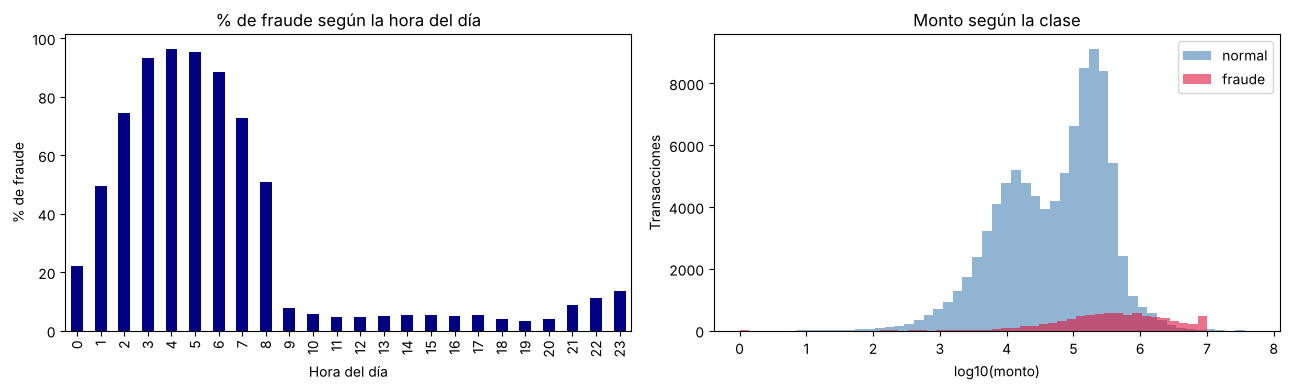

In [7]:
pay["hora"] = pay["step"] % 24                       # resto de dividir para 24 = hora del día (0 a 23)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(pay.groupby("hora")["isFraud"].mean() * 100).plot(kind="bar", color="navy", ax=ax[0])
ax[0].set(title="% de fraude según la hora del día", xlabel="Hora del día", ylabel="% de fraude")
for clase, color, etiqueta in [(0, "steelblue", "normal"), (1, "crimson", "fraude")]:
    ax[1].hist(np.log10(pay.loc[pay["isFraud"] == clase, "amount"] + 1), bins=50, alpha=0.6, color=color, label=etiqueta)
ax[1].set(title="Monto según la clase", xlabel="log10(monto)", ylabel="Transacciones"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretación.** De madrugada (2 a 7 h) casi todas las transacciones de la muestra son fraude: la actividad normal ocurre de día y los defraudadores de la simulación operan a cualquier hora. Los fraudes suelen tener montos más altos. Ya tenemos tres señales: **tipo, monto y hora**.

## A.3 Limpiar y preparar, paso a paso

**Paso 1: faltantes y duplicados.**

In [8]:
print("Valores faltantes por columna:", int(pay.isna().sum().sum()))
print("Filas duplicadas:", int(pay.duplicated().sum()))

Valores faltantes por columna: 0
Filas duplicadas: 0


**Paso 2: crear variables útiles.** `step` tal cual no sirve (la «hora 600 del mes» no se repite), pero la **hora del día** sí. Y como el fraude solo usa dos tipos, creamos `transfer_o_retiro` = 1 si el tipo es `TRANSFER` o `CASH_OUT`. Esto se llama **ingeniería de variables**. Mira el antes y el después:

In [9]:
pay["transfer_o_retiro"] = pay["type"].isin(["TRANSFER", "CASH_OUT"]).astype(int)   # 1 si es uno de esos dos tipos
pay[["step", "hora", "type", "transfer_o_retiro"]].head(8)

,step,hora,type,transfer_o_retiro
0,1,1,TRANSFER,1
1,1,1,CASH_OUT,1
2,1,1,PAYMENT,0
3,1,1,CASH_OUT,1
4,1,1,TRANSFER,1
5,1,1,CASH_OUT,1
6,1,1,TRANSFER,1
7,1,1,CASH_IN,0


**Paso 3: revisar fugas de información.** Una fuga es una columna que contiene la respuesta o que se escribió conociéndola. *Analogía:* predecir si un estudiante aprueba usando su «nota final». El propio dataset advierte que **las transacciones detectadas como fraude se cancelan**, y eso altera las cuatro columnas de saldo. Comprobemos qué tan sospechosas son:

In [10]:
fr = pay[pay["isFraud"] == 1]; no = pay[pay["isFraud"] == 0]
print(f"Fraudes cuyo monto es igual al saldo anterior: {(fr['amount'] == fr['oldbalanceOrg']).mean():.1%}")
print(f"Normales cuyo monto es igual al saldo anterior: {(no['amount'] == no['oldbalanceOrg']).mean():.1%}")

Fraudes cuyo monto es igual al saldo anterior: 97.8%
Normales cuyo monto es igual al saldo anterior: 0.0%


Una sola comparación casi separa las clases: es la huella de la simulación, no algo que tendríamos en la vida real al momento de decidir. **Quitamos los saldos.** En A.4 veremos cuánto «mejoraría» el modelo si los dejáramos (demasiado bueno para ser verdad).

**Paso 4: otra fuga escondida.** Un fraude aparece **dos veces**: un `TRANSFER` y un `CASH_OUT` con el mismo monto y en la misma hora.

In [11]:
pares = fr.groupby(["step", "amount"]).size()      # agrupar fraudes por hora y monto
print("Fraudes:", len(fr), "| operaciones distintas:", len(pares), "| operaciones con dos filas:", int((pares == 2).sum()))

Fraudes: 8213 | operaciones distintas: 4080 | operaciones con dos filas: 4000


Si dividimos las filas al azar, una «pata» del fraude puede quedar en Train y la otra en Validation: el árbol memorizaría el monto exacto y lo «reconocería». Por eso dividiremos **por operación**: las dos filas de un fraude quedan siempre juntas.

**Paso 5: ¿hay que escalar?** Para un **árbol, no**: sus preguntas son del tipo «¿monto ≤ 200 000?», y la respuesta no cambia si medimos en dólares o en miles de dólares. Lo comprobaremos en A.6. Para KNN y SVM sí hará falta (partes B y C).

**Paso 6: el desbalance.** Hay 8,2 % de fraudes. Lo tendremos en cuenta al medir (F1, no Accuracy) y probaremos formas de balancear en A.10.

**Paso 7: la tabla final para el modelo.** Tres variables de entrada (`X`) y la respuesta (`y`):

In [12]:
FEAT_PAY = ["transfer_o_retiro", "amount", "hora"]     # variables de entrada
pay[FEAT_PAY + ["isFraud"]].head()

,transfer_o_retiro,amount,hora,isFraud
0,1,181.00,1,1
1,1,181.00,1,1
2,0,5213.25,1,0
3,1,193605.38,1,0
4,1,2806.00,1,1


## A.4 Dividir en Train, Validation y Test, y la línea base

- **Train (70 %)**: para aprender. **Validation (15 %)**: para comparar modelos e hiperparámetros. **Test (15 %)**: el examen final, **una sola vez** (Parte D).
- Usamos `GroupShuffleSplit`: divide **por grupos** (operaciones) en lugar de por filas.

In [13]:
# Identificador de operación: las dos filas de un fraude comparten hora y monto; cada normal es su propia operación
pay["operacion"] = np.where(pay["isFraud"] == 1,
                            "f" + pay["step"].astype(str) + "_" + pay["amount"].astype(str),
                            "n" + pay.index.astype(str))

corte1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)        # 70 % / 30 %
idx_train, idx_rest = next(corte1.split(pay, groups=pay["operacion"]))
train_pay, rest_pay = pay.iloc[idx_train], pay.iloc[idx_rest]
corte2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)        # el 30 % en dos mitades
idx_val, idx_test = next(corte2.split(rest_pay, groups=rest_pay["operacion"]))
val_pay, test_pay = rest_pay.iloc[idx_val], rest_pay.iloc[idx_test]

X_train_pay, y_train_pay = train_pay[FEAT_PAY], train_pay["isFraud"]
X_val_pay, y_val_pay = val_pay[FEAT_PAY], val_pay["isFraud"]
X_test_pay, y_test_pay = test_pay[FEAT_PAY], test_pay["isFraud"]
for nombre, parte in [("Train", train_pay), ("Validation", val_pay), ("Test", test_pay)]:
    print(f"{nombre:10s}: {len(parte):6d} filas, {int(parte['isFraud'].sum()):5d} fraudes ({parte['isFraud'].mean():.1%})")
print("Operaciones compartidas entre Train y Validation:", len(set(train_pay["operacion"]) & set(val_pay["operacion"])))

Train     :  70126 filas,  5735 fraudes (8.2%)
Validation:  15063 filas,  1283 fraudes (8.5%)
Test      :  15009 filas,  1195 fraudes (8.0%)
Operaciones compartidas entre Train y Validation: 0


**Línea base.** Antes de cualquier modelo, dos referencias: decir siempre «no fraude» (`DummyClassifier`) y la regla actual del negocio (`isFlaggedFraud`). Todo modelo debe superarlas.

In [14]:
base_pay = DummyClassifier(strategy="most_frequent").fit(X_train_pay, y_train_pay)   # aprende la clase más frecuente
res_base_pay = evaluar(base_pay, "Línea base: siempre «no fraude»", X_train_pay, y_train_pay, X_val_pay, y_val_pay)
pred_regla = val_pay["isFlaggedFraud"].to_numpy()                                       # la regla ya viene en los datos
m_regla = metricas(y_val_pay, pred_regla)
res_regla = {"modelo": "Regla isFlaggedFraud", "f1_train": np.nan, "f1_val": m_regla["f1"], "brecha": np.nan,
             "precision_val": m_regla["precision"], "recall_val": m_regla["recall"],
             "accuracy_val": m_regla["accuracy"], "alertas_val": int(pred_regla.sum())}
tabla([res_base_pay, res_regla])

,f1_train,f1_val,brecha,precision_val,recall_val,accuracy_val,alertas_val
modelo,,,,,,,
Línea base: siempre «no fraude»,0.0,0.000,0.0,0.0,0.000,0.915,0
Regla isFlaggedFraud,NaN,0.008,NaN,1.0,0.004,0.915,5


**Lee la tabla.** El «siempre no fraude» tiene Accuracy alta (≈ 0,915) pero F1 = 0: no encuentra ningún fraude. La regla emite muy pocas alertas: acierta cuando avisa, pero casi nunca avisa (F1 ≈ 0,01). Ahora, la prueba de la fuga de saldos que anunciamos:

In [15]:
SALDOS = ["oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
for nombre, cols in [("Sin saldos (correcto)", FEAT_PAY), ("Con los saldos (fuga)", FEAT_PAY + SALDOS)]:
    m = DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=42).fit(train_pay[cols], y_train_pay)
    print(f"{nombre:24s} F1 en Validation = {f1_score(y_val_pay, m.predict(val_pay[cols])):.3f}")

Sin saldos (correcto)    F1 en Validation = 0.633


Con los saldos (fuga)    F1 en Validation = 0.884


Con los saldos el F1 salta de ≈ 0,63 a ≈ 0,88: **demasiado bueno para ser verdad**. Seguimos sin saldos.

## A.5 El árbol a mano: el índice de Gini

Un árbol hace preguntas de sí o no. Para elegir la mejor pregunta mide la **mezcla de clases** con el índice de Gini: $G=1-p_0^2-p_1^2$, donde $p_0$ y $p_1$ son las proporciones de normales y fraudes en el nodo. Vale 0 si el nodo es puro y 0,5 si es mitad y mitad.

**Ejemplo con 20 transacciones (16 normales, 4 fraudes):** $G=1-0{,}8^2-0{,}2^2=0{,}32$. La pregunta «¿es TRANSFER?» deja 6 transacciones (2 normales, 4 fraudes, $G=0{,}444$) y 14 (14 normales, $G=0$). **Gini ponderado** $=\tfrac{6}{20}(0{,}444)+\tfrac{14}{20}(0)=0{,}133$. Reducción: $0{,}32-0{,}133=0{,}187$. El árbol prueba muchas preguntas y elige la de **mayor reducción** (menor Gini ponderado).

In [16]:
def gini(conteos):
    p = np.asarray(conteos) / sum(conteos)       # proporciones de cada clase
    return 1 - np.sum(p ** 2)                     # 1 − suma de proporciones al cuadrado

print("Gini del ejemplo (16, 4):", round(gini([16, 4]), 3))
print("Gini ponderado de «¿es TRANSFER?»:", round(6 / 20 * gini([2, 4]) + 14 / 20 * gini([14, 0]), 3))

def evaluar_pregunta(columna, umbral):
    # Divide Train en dos ramas según la pregunta y calcula el Gini de cada una
    izq = y_train_pay[X_train_pay[columna] <= umbral]
    der = y_train_pay[X_train_pay[columna] > umbral]
    g_izq, g_der = gini([(izq == 0).sum(), izq.sum()]), gini([(der == 0).sum(), der.sum()])
    return {"pregunta": f"¿{columna} <= {umbral}?", "filas_izq": len(izq), "fraudes_izq": int(izq.sum()), "gini_izq": g_izq,
            "filas_der": len(der), "fraudes_der": int(der.sum()), "gini_der": g_der,
            "gini_ponderado": (len(izq) * g_izq + len(der) * g_der) / len(y_train_pay)}

print("Gini de la raíz (todo Train):", round(gini([(y_train_pay == 0).sum(), y_train_pay.sum()]), 3))
pd.DataFrame([evaluar_pregunta("transfer_o_retiro", 0.5), evaluar_pregunta("amount", 200000),
              evaluar_pregunta("hora", 6.5), evaluar_pregunta("hora", 8.5)]).round(3).sort_values("gini_ponderado")

Gini del ejemplo (16, 4): 0.32
Gini ponderado de «¿es TRANSFER?»: 0.133
Gini de la raíz (todo Train): 0.15


,pregunta,filas_izq,fraudes_izq,gini_izq,filas_der,fraudes_der,gini_der,gini_ponderado
3,¿hora <= 8.5?,3591,2072,0.488,66535,3663,0.104,0.124
2,¿hora <= 6.5?,2762,1591,0.488,67364,4144,0.115,0.130
0,¿transfer_o_retiro <= 0.5?,36355,0,0.000,33771,5735,0.282,0.136
1,¿amount <= 200000?,49488,1905,0.074,20638,3830,0.302,0.141


**Lee la tabla.** De las cuatro preguntas, «¿hora ≤ 8,5?» deja el menor Gini ponderado: es la que mejor separa. Veamos si el algoritmo llega a la misma conclusión.

## A.6 El modelo más simple con scikit-learn

Crear un modelo en scikit-learn siempre tiene **tres pasos**: (1) **crear** el objeto con sus hiperparámetros, (2) **entrenar** con `fit` usando Train y (3) **predecir** con `predict`.

Primeras 10 predicciones: [1 1 1 1 1 1 0 0 1 0]
Primeras 10 respuestas reales: [0 0 0 1 1 0 0 0 1 0]


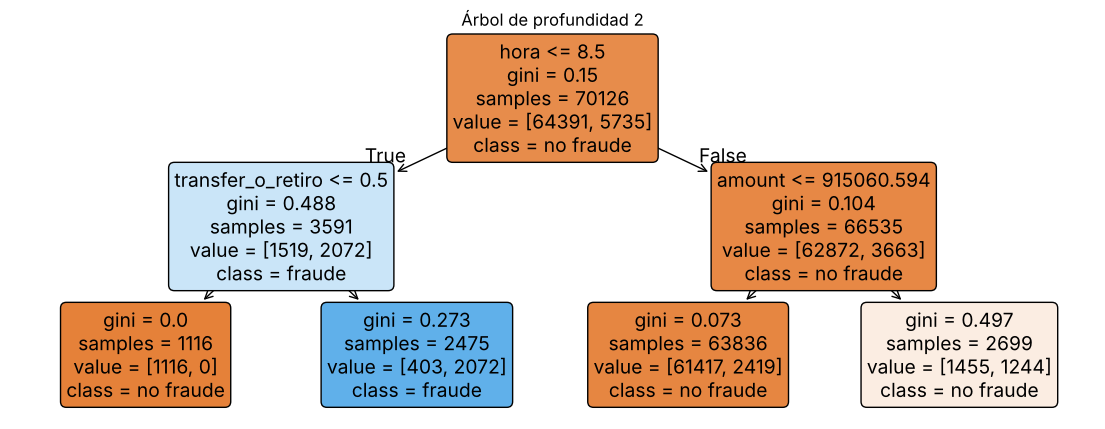

In [17]:
arbol_simple = DecisionTreeClassifier(max_depth=2, random_state=42)   # 1) crear: un árbol de solo 2 preguntas de profundidad
arbol_simple.fit(X_train_pay, y_train_pay)                            # 2) entrenar: aprende las preguntas con Train
pred_val_simple = arbol_simple.predict(X_val_pay)                     # 3) predecir: 0 o 1 para cada transacción de Validation

print("Primeras 10 predicciones:", pred_val_simple[:10])
print("Primeras 10 respuestas reales:", y_val_pay.values[:10])

plt.figure(figsize=(14, 5))
plot_tree(arbol_simple, feature_names=FEAT_PAY, class_names=["no fraude", "fraude"], filled=True, rounded=True, precision=3)
plt.title("Árbol de profundidad 2"); plt.show()

**Lee el árbol.** La primera pregunta es la misma que ganó a mano: **¿hora ≤ 8,5?** Cada cuadro muestra la pregunta, el Gini, cuántas transacciones llegan (`samples`), cuántas de cada clase (`value`) y la clase que predice. Comprobemos también que **escalar no cambia nada en un árbol**:

In [18]:
X_train_miles = X_train_pay.assign(amount=X_train_pay["amount"] / 1000)     # monto en miles
X_val_miles = X_val_pay.assign(amount=X_val_pay["amount"] / 1000)
arbol_miles = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X_train_miles, y_train_pay)
print("¿Predicciones idénticas con el monto en miles?", (arbol_miles.predict(X_val_miles) == pred_val_simple).all())

¿Predicciones idénticas con el monto en miles? True


## A.7 Las métricas: a mano y con scikit-learn, en Train y en Validation

Primero la matriz de confusión de Validation y las métricas calculadas a mano.

In [19]:
matriz = confusion_matrix(y_val_pay, pred_val_simple, labels=[0, 1])   # filas: real; columnas: predicho
vn, fp, fn, vp = matriz.ravel()                                        # las cuatro casillas
print(pd.DataFrame(matriz, index=["real normal", "real fraude"], columns=["pred normal", "pred fraude"]))
print(f"\nA mano: Accuracy  = ({vp} + {vn}) / {vn + fp + fn + vp} = {(vp + vn) / (vn + fp + fn + vp):.3f}")
print(f"        Precision = {vp} / ({vp} + {fp}) = {vp / (vp + fp):.3f}")
print(f"        Recall    = {vp} / ({vp} + {fn}) = {vp / (vp + fn):.3f}")
print(f"        F1        = 2·{vp} / (2·{vp} + {fp} + {fn}) = {2 * vp / (2 * vp + fp + fn):.3f}")
print("\nCon scikit-learn:", {k: round(v, 3) for k, v in metricas(y_val_pay, pred_val_simple).items()})

             pred normal  pred fraude
real normal        13698           82
real fraude          775          508

A mano: Accuracy  = (508 + 13698) / 15063 = 0.943
        Precision = 508 / (508 + 82) = 0.861
        Recall    = 508 / (508 + 775) = 0.396
        F1        = 2·508 / (2·508 + 82 + 775) = 0.542

Con scikit-learn: {'accuracy': 0.943, 'precision': 0.861, 'recall': 0.396, 'f1': 0.542}


Los números a mano y los de scikit-learn coinciden. Ahora lo más importante: **¿funciona igual en Train que en Validation?** Si en Train fuera mucho mejor, estaría memorizando.

In [20]:
res_simple = evaluar(arbol_simple, "Árbol simple (profundidad 2)", X_train_pay, y_train_pay, X_val_pay, y_val_pay)
tabla([res_base_pay, res_regla, res_simple])

,f1_train,f1_val,brecha,precision_val,recall_val,accuracy_val,alertas_val
modelo,,,,,,,
Línea base: siempre «no fraude»,0.000,0.000,0.000,0.000,0.000,0.915,0
Regla isFlaggedFraud,NaN,0.008,NaN,1.000,0.004,0.915,5
Árbol simple (profundidad 2),0.505,0.542,-0.038,0.861,0.396,0.943,590


**Interpretación.** El árbol de profundidad 2 ya supera a las dos referencias en F1, y su F1 en Train y en Validation es parecido (brecha pequeña): no memoriza. Pero es muy simple. ¿Mejora si lo dejamos crecer? Para eso están los hiperparámetros.

## A.8 Los hiperparámetros del árbol, uno por uno

| Hiperparámetro | Qué controla | Si lo subo… | Valor por defecto |
|---|---|---|---|
| `max_depth` | Cuántas preguntas seguidas puede hacer | Árbol más complejo; puede memorizar | `None` (sin límite) |
| `min_samples_leaf` | Mínimo de filas que debe tener cada hoja | Hojas más grandes y estables; árbol más simple | 1 |
| `min_samples_split` | Mínimo de filas que debe tener un nodo para dividirse | Menos divisiones; árbol más simple | 2 |
| `criterion` | Cómo mide la mezcla: `"gini"` o `"entropy"` | Casi siempre dan árboles parecidos | `"gini"` |
| `class_weight` | Peso de cada clase; `"balanced"` da más peso a la clase rara | Más alertas: sube Recall y baja Precision | `None` |
| `random_state` | Semilla para que el resultado se pueda repetir | No cambia la calidad | — |

Veamos el efecto de cada uno en el tamaño del árbol:

In [21]:
configs = [("Por defecto (sin límites)", {}),
           ("max_depth=5", {"max_depth": 5}),
           ("min_samples_leaf=200", {"min_samples_leaf": 200}),
           ("min_samples_split=2000", {"min_samples_split": 2000}),
           ("criterion='entropy', max_depth=5", {"criterion": "entropy", "max_depth": 5}),
           ("class_weight='balanced', max_depth=5", {"class_weight": "balanced", "max_depth": 5})]
filas = []
for nombre, params in configs:
    m = DecisionTreeClassifier(random_state=42, **params).fit(X_train_pay, y_train_pay)   # **params desempaca el diccionario
    fila = evaluar(m, nombre, X_train_pay, y_train_pay, X_val_pay, y_val_pay)
    fila["hojas"] = m.get_n_leaves(); fila["profundidad"] = m.get_depth()
    filas.append(fila)
tabla(filas)[["hojas", "profundidad", "f1_train", "f1_val", "brecha", "precision_val", "recall_val"]]

,hojas,profundidad,f1_train,f1_val,brecha,precision_val,recall_val
modelo,,,,,,,
Por defecto (sin límites),3413,70,0.998,0.534,0.464,0.626,0.465
max_depth=5,21,5,0.610,0.633,-0.022,0.806,0.521
min_samples_leaf=200,123,22,0.604,0.632,-0.028,0.800,0.522
min_samples_split=2000,61,31,0.602,0.635,-0.034,0.788,0.532
"criterion='entropy', max_depth=5",17,5,0.616,0.634,-0.018,0.796,0.527
"class_weight='balanced', max_depth=5",17,5,0.474,0.486,-0.011,0.347,0.808


**Lee la tabla.** Sin límites, el árbol crece hasta miles de hojas, tiene F1 casi perfecto en Train y mucho peor en Validation: **memoriza** (brecha grande). Cualquiera de los límites lo controla. `class_weight="balanced"` cambia el tipo de error: más alertas, más Recall, menos Precision.

## A.9 Probar combinaciones con un `for`

En lugar de probar a ciegas, recorremos una **rejilla** de valores de `max_depth` y `min_samples_leaf`, entrenamos un árbol con cada combinación y lo medimos en Train y Validation.

In [22]:
filas = []
for profundidad in [2, 3, 4, 5, 6, 8, 10, None]:            # None = sin límite
    for hoja in [1, 30, 200]:
        m = DecisionTreeClassifier(max_depth=profundidad, min_samples_leaf=hoja, random_state=42)
        m.fit(X_train_pay, y_train_pay)
        fila = evaluar(m, f"prof={profundidad}, hoja={hoja}", X_train_pay, y_train_pay, X_val_pay, y_val_pay)
        fila.update({"max_depth": "sin límite" if profundidad is None else profundidad, "min_samples_leaf": hoja, "hojas": m.get_n_leaves()})
        filas.append(fila)
rejilla_arbol = pd.DataFrame(filas)
print("F1 en Validation (filas: max_depth, columnas: min_samples_leaf):")
rejilla_arbol.pivot(index="max_depth", columns="min_samples_leaf", values="f1_val").round(3)

F1 en Validation (filas: max_depth, columnas: min_samples_leaf):


min_samples_leaf,1,30,200
max_depth,,,
2,0.542,0.542,0.542
3,0.637,0.637,0.637
4,0.633,0.633,0.639
5,0.633,0.633,0.632
6,0.627,0.635,0.632
8,0.613,0.629,0.632
10,0.601,0.627,0.632
sin límite,0.534,0.621,0.632


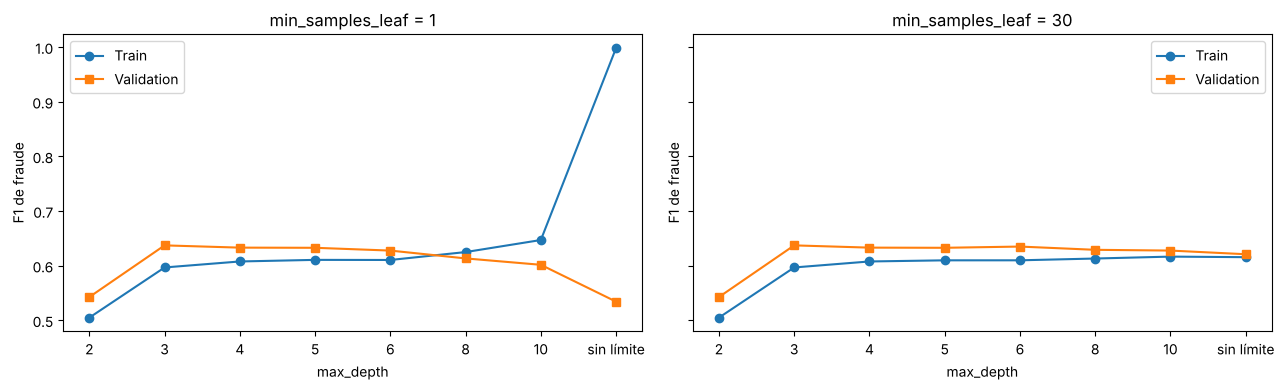

Mejor combinación en Validation: prof=4, hoja=200 | F1 val = 0.639 | brecha = -0.028


In [23]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for i, hoja in enumerate([1, 30]):
    d = rejilla_arbol[rejilla_arbol["min_samples_leaf"] == hoja]
    etiquetas = d["max_depth"].astype(str)
    ax[i].plot(etiquetas, d["f1_train"], marker="o", label="Train")
    ax[i].plot(etiquetas, d["f1_val"], marker="s", label="Validation")
    ax[i].set(title=f"min_samples_leaf = {hoja}", xlabel="max_depth", ylabel="F1 de fraude"); ax[i].legend()
plt.tight_layout(); plt.show()
mejor_arbol_fila = rejilla_arbol.sort_values("f1_val", ascending=False).iloc[0]
print("Mejor combinación en Validation:", mejor_arbol_fila["modelo"], "| F1 val =", round(mejor_arbol_fila["f1_val"], 3),
      "| brecha =", round(mejor_arbol_fila["brecha"], 3))

**Cómo leer las curvas.** Con `min_samples_leaf = 1` (izquierda), al aumentar la profundidad Train sigue subiendo y Validation cae: las curvas se separan, el árbol memoriza. Con `min_samples_leaf = 30` (derecha), las curvas van mucho más juntas: las hojas grandes impiden memorizar. Varias combinaciones quedan muy cerca (F1 entre 0,63 y 0,64): elegimos la de **mejor F1 en Validation con brecha pequeña**. Todas superan a la línea base (F1 = 0) y a la regla (≈ 0,01).

In [24]:
# Fijamos el árbol elegido (el mejor de la rejilla) para el resto de la Parte A
ARBOL_PARAMS = {"max_depth": None if mejor_arbol_fila["max_depth"] == "sin límite" else int(mejor_arbol_fila["max_depth"]),
                "min_samples_leaf": int(mejor_arbol_fila["min_samples_leaf"])}
print("Árbol elegido:", ARBOL_PARAMS)
arbol_pay = DecisionTreeClassifier(random_state=42, **ARBOL_PARAMS).fit(X_train_pay, y_train_pay)
res_arbol = evaluar(arbol_pay, f"Árbol elegido {ARBOL_PARAMS}", X_train_pay, y_train_pay, X_val_pay, y_val_pay)
tabla([res_base_pay, res_regla, res_simple, res_arbol])

Árbol elegido: {'max_depth': 4, 'min_samples_leaf': 200}


,f1_train,f1_val,brecha,precision_val,recall_val,accuracy_val,alertas_val
modelo,,,,,,,
Línea base: siempre «no fraude»,0.000,0.000,0.000,0.000,0.000,0.915,0
Regla isFlaggedFraud,NaN,0.008,NaN,1.000,0.004,0.915,5
Árbol simple (profundidad 2),0.505,0.542,-0.038,0.861,0.396,0.943,590
"Árbol elegido {'max_depth': 4, 'min_samples_leaf': 200}",0.610,0.639,-0.028,0.774,0.544,0.948,902


## A.10 Datos desbalanceados: cuatro estrategias

Con 8,2 % de fraudes el modelo tiende a decir «normal». Cuatro formas de tratarlo, **siempre solo en Train** (Validation y Test deben parecerse a la realidad):

1. **Sin balancear.**
2. **`class_weight="balanced"`**: cada fraude pesa más al elegir las preguntas. Peso = filas / (2 × filas de la clase).
3. **Sobremuestreo**: repetir fraudes de Train al azar hasta igualar a los normales.
4. **Submuestreo**: quitar normales de Train al azar hasta igualar a los fraudes.

Primero veamos cómo cambian los datos de Train con cada técnica:

In [25]:
entreno = X_train_pay.assign(isFraud=y_train_pay.values)            # juntamos X e y para muestrear filas completas
normales = entreno[entreno["isFraud"] == 0]
fraudes = entreno[entreno["isFraud"] == 1]
peso_fraude = len(entreno) / (2 * len(fraudes)); peso_normal = len(entreno) / (2 * len(normales))
print(f"class_weight balanced → peso de un fraude = {peso_fraude:.2f}, peso de un normal = {peso_normal:.3f}")

sobre = pd.concat([normales, resample(fraudes, replace=True, n_samples=len(normales), random_state=42)])   # repetir fraudes
sub = pd.concat([resample(normales, replace=False, n_samples=len(fraudes), random_state=42), fraudes])     # quitar normales
for nombre, d in [("Train original", entreno), ("Sobremuestreo", sobre), ("Submuestreo", sub)]:
    print(f"{nombre:15s}: {len(d):6d} filas | normales {int((d['isFraud'] == 0).sum()):6d} | fraudes {int(d['isFraud'].sum()):6d} | {d['isFraud'].mean():.0%} fraude")

class_weight balanced → peso de un fraude = 6.11, peso de un normal = 0.545
Train original :  70126 filas | normales  64391 | fraudes   5735 | 8% fraude
Sobremuestreo  : 128782 filas | normales  64391 | fraudes  64391 | 50% fraude
Submuestreo    :  11470 filas | normales   5735 | fraudes   5735 | 50% fraude


In [26]:
estrategias = [
    ("Sin balancear", DecisionTreeClassifier(random_state=42, **ARBOL_PARAMS).fit(X_train_pay, y_train_pay)),
    ("class_weight balanced", DecisionTreeClassifier(random_state=42, class_weight="balanced", **ARBOL_PARAMS).fit(X_train_pay, y_train_pay)),
    ("Sobremuestreo", DecisionTreeClassifier(random_state=42, **ARBOL_PARAMS).fit(sobre[FEAT_PAY], sobre["isFraud"])),
    ("Submuestreo", DecisionTreeClassifier(random_state=42, **ARBOL_PARAMS).fit(sub[FEAT_PAY], sub["isFraud"]))]
# Medimos todas en el Train ORIGINAL y en la MISMA Validation
tabla([evaluar(m, n, X_train_pay, y_train_pay, X_val_pay, y_val_pay) for n, m in estrategias])

,f1_train,f1_val,brecha,precision_val,recall_val,accuracy_val,alertas_val
modelo,,,,,,,
Sin balancear,0.610,0.639,-0.028,0.774,0.544,0.948,902
class_weight balanced,0.534,0.545,-0.010,0.429,0.747,0.894,2235
Sobremuestreo,0.533,0.544,-0.011,0.427,0.748,0.893,2247
Submuestreo,0.533,0.544,-0.011,0.427,0.748,0.893,2247


**Interpretación.** Las tres técnicas de balanceo suben mucho el **Recall** (se escapan menos fraudes) a cambio de bajar la **Precision** (más falsas alarmas). El F1 baja porque las falsas alarmas crecen mucho. ¿Cuál conviene? Depende del costo: si un fraude perdido cuesta mucho más que revisar una alerta, una estrategia balanceada puede ser mejor aunque su F1 sea menor. Con F1 como criterio, nos quedamos **sin balancear**.

## A.11 Random Forest: muchos árboles que votan

**A mano.** Un bosque entrena muchos árboles distintos: cada uno ve una muestra al azar de Train (con reemplazo) y, en cada pregunta, solo algunas variables al azar. Para una transacción nueva **cada árbol vota** y gana la mayoría. Si 3 de 5 árboles dicen «fraude», el bosque dice fraude.

In [27]:
votos = np.array([1, 0, 1, 1, 0])                 # lo que dijo cada uno de 5 árboles (ilustrativo)
print("Votos por fraude:", votos.sum(), "de", len(votos), "→ el bosque predice", "fraude" if votos.mean() > 0.5 else "normal")

bosque_simple = RandomForestClassifier(random_state=42, n_jobs=-1)        # 1) crear con valores por defecto (100 árboles, sin límite)
bosque_simple.fit(X_train_pay, y_train_pay)                               # 2) entrenar
votos_reales = np.array([t.predict(X_val_pay.iloc[[0]].values)[0] for t in bosque_simple.estimators_])
print("Primera transacción de Validation: votos por fraude =", int(votos_reales.sum()), "de", len(votos_reales),
      "→ predicción del bosque:", bosque_simple.predict(X_val_pay.iloc[[0]])[0])
res_bosque_simple = evaluar(bosque_simple, "Bosque por defecto", X_train_pay, y_train_pay, X_val_pay, y_val_pay)
tabla([res_arbol, res_bosque_simple])

Votos por fraude: 3 de 5 → el bosque predice fraude


Primera transacción de Validation: votos por fraude = 44 de 100 → predicción del bosque: 0


,f1_train,f1_val,brecha,precision_val,recall_val,accuracy_val,alertas_val
modelo,,,,,,,
"Árbol elegido {'max_depth': 4, 'min_samples_leaf': 200}",0.610,0.639,-0.028,0.774,0.544,0.948,902
Bosque por defecto,0.998,0.539,0.459,0.628,0.472,0.931,965


**Interpretación.** Con los valores por defecto cada árbol crece sin límite: el bosque memoriza (F1 casi perfecto en Train y brecha grande), igual que un árbol sin límite. El voto no basta: hay que limitar los árboles.

### Los hiperparámetros del Random Forest

| Hiperparámetro | Qué controla | Valor por defecto |
|---|---|---|
| `n_estimators` | Cuántos árboles votan. Más árboles = votación más estable (y más lenta) | 100 |
| `max_depth`, `min_samples_leaf` | Los mismos controles del árbol, aplicados a cada árbol | sin límite, 1 |
| `max_features` | Cuántas variables puede mirar cada pregunta (azar que hace distintos a los árboles) | `"sqrt"` |
| `class_weight` | Igual que en el árbol | `None` |
| `n_jobs` | Cuántos núcleos usa para entrenar (−1 = todos) | 1 |

In [28]:
filas = []
for n_arboles in [50, 200]:
    for profundidad in [5, 8, 12, None]:
        m = RandomForestClassifier(n_estimators=n_arboles, max_depth=profundidad, min_samples_leaf=5,
                                   random_state=42, n_jobs=-1).fit(X_train_pay, y_train_pay)
        filas.append(evaluar(m, f"árboles={n_arboles}, prof={profundidad}", X_train_pay, y_train_pay, X_val_pay, y_val_pay))
rejilla_bosque = tabla(filas)
rejilla_bosque[["f1_train", "f1_val", "brecha", "precision_val", "recall_val"]]

,f1_train,f1_val,brecha,precision_val,recall_val
modelo,,,,,
"árboles=50, prof=5",0.601,0.629,-0.028,0.832,0.505
"árboles=50, prof=8",0.617,0.626,-0.009,0.820,0.506
"árboles=50, prof=12",0.657,0.630,0.026,0.812,0.515
"árboles=50, prof=None",0.717,0.624,0.093,0.784,0.519
"árboles=200, prof=5",0.601,0.626,-0.025,0.824,0.505
"árboles=200, prof=8",0.620,0.626,-0.006,0.823,0.506
"árboles=200, prof=12",0.657,0.634,0.023,0.816,0.518
"árboles=200, prof=None",0.716,0.630,0.086,0.790,0.525


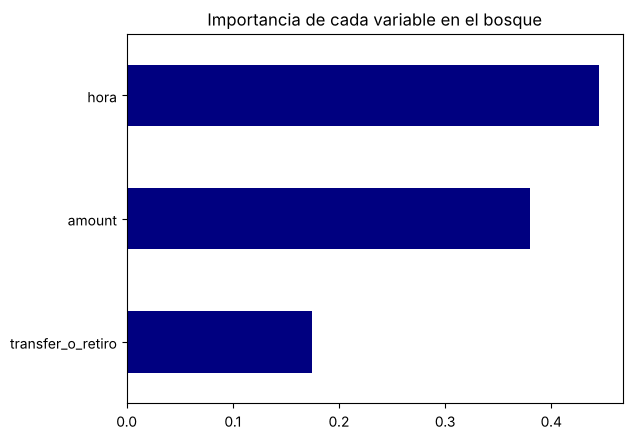

transfer_o_retiro    0.175
amount               0.380
hora                 0.445
dtype: float64


In [29]:
BOSQUE_PARAMS = {"n_estimators": 200, "max_depth": 8, "min_samples_leaf": 5}
bosque_pay = RandomForestClassifier(random_state=42, n_jobs=-1, **BOSQUE_PARAMS).fit(X_train_pay, y_train_pay)
res_bosque = evaluar(bosque_pay, "Bosque elegido (200 árboles, prof=8)", X_train_pay, y_train_pay, X_val_pay, y_val_pay)
importancia = pd.Series(bosque_pay.feature_importances_, index=FEAT_PAY).sort_values()
importancia.plot(kind="barh", color="navy", title="Importancia de cada variable en el bosque"); plt.show()
print(importancia.round(3))

**Interpretación.** Con profundidad limitada la brecha desaparece. Pasar de 50 a 200 árboles casi no cambia el resultado: más árboles estabilizan, pero no hacen milagros. La **importancia** dice cuánto redujo el Gini cada variable en todos los árboles: la hora es la más usada, coherente con la primera pregunta del árbol. Importancia no es causalidad.

## A.12 Modelo final de PaySim

In [30]:
final_pay = tabla([res_base_pay, res_regla, res_simple, res_arbol, res_bosque])
final_pay[["f1_train", "f1_val", "brecha", "precision_val", "recall_val", "alertas_val"]]

,f1_train,f1_val,brecha,precision_val,recall_val,alertas_val
modelo,,,,,,
Línea base: siempre «no fraude»,0.000,0.000,0.000,0.000,0.000,0
Regla isFlaggedFraud,NaN,0.008,NaN,1.000,0.004,5
Árbol simple (profundidad 2),0.505,0.542,-0.038,0.861,0.396,590
"Árbol elegido {'max_depth': 4, 'min_samples_leaf': 200}",0.610,0.639,-0.028,0.774,0.544,902
"Bosque elegido (200 árboles, prof=8)",0.620,0.626,-0.006,0.823,0.506,789


**Conclusión de la Parte A.** El árbol elegido y el bosque tienen un F1 en Validation muy parecido (entre 0,63 y 0,64) y brecha casi nula. Ante un empate, preferimos el **árbol**: es más simple y se puede explicar pregunta por pregunta a un comité de riesgo. Ambos superan claramente a la línea base y a la regla actual. Detectan cerca de la mitad de los fraudes y, cuando avisan, aciertan 8 de cada 10 veces. **Test** se abrirá una sola vez en la Parte D.

# Parte B · BankChurners: KNN, clasificar por parecido

**El problema.** Un banco quiere anticipar qué clientes abandonarán su tarjeta de crédito para acercarse a tiempo con mejores condiciones.

**El dataset.** 10 127 clientes de tarjeta de crédito (Kaggle, a partir del sitio LEAPS de Analyttica) con edad, ingreso, tipo de tarjeta, límite y su **comportamiento del último año**: cuántas transacciones hizo, por cuánto, cuántos meses estuvo inactivo, etc. Solo el 16,1 % abandonó: otro dataset desbalanceado.

**Por qué KNN.** KNN (*k vecinos más cercanos*) responde «¿qué hicieron los clientes que más se parecen a este?». Con datos de comportamiento, esa idea es natural.

## B.1 Mirar los datos

In [31]:
churn = pd.read_csv(ARCHIVO_CHURN)
print("Filas y columnas:", churn.shape)
churn.head()

Filas y columnas: (10127, 23)


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [32]:
churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  str    
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                                      

**Lee la salida.** Hay 23 columnas: un identificador (`CLIENTNUM`), la respuesta (`Attrition_Flag`), datos demográficos (texto) y numéricos de comportamiento. Las dos últimas, `Naive_Bayes_Classifier_…`, son raras: las revisaremos en la limpieza.

## B.2 Entender y graficar

In [33]:
print(churn["Attrition_Flag"].value_counts())
print("\nProporción de abandono:", round((churn["Attrition_Flag"] == "Attrited Customer").mean() * 100, 1), "%")
# Promedios de algunas variables según la clase
churn.groupby("Attrition_Flag")[["Total_Trans_Ct", "Total_Trans_Amt", "Total_Revolving_Bal", "Months_Inactive_12_mon", "Contacts_Count_12_mon"]].mean().round(1)

Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64

Proporción de abandono: 16.1 %


,Total_Trans_Ct,Total_Trans_Amt,Total_Revolving_Bal,Months_Inactive_12_mon,Contacts_Count_12_mon
Attrition_Flag,,,,,
Attrited Customer,44.9,3095.0,672.8,2.7,3.0
Existing Customer,68.7,4654.7,1256.6,2.3,2.4


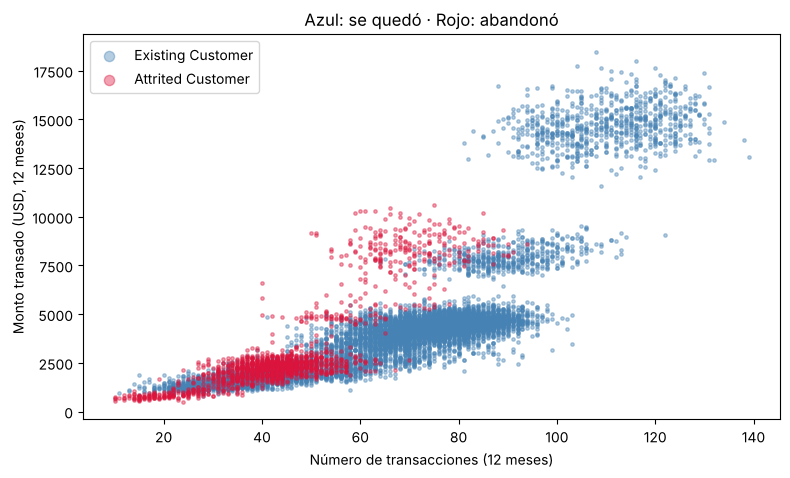

In [34]:
fig, ax = plt.subplots(figsize=(9, 5))
for clase, color in [("Existing Customer", "steelblue"), ("Attrited Customer", "crimson")]:
    d = churn[churn["Attrition_Flag"] == clase]
    ax.scatter(d["Total_Trans_Ct"], d["Total_Trans_Amt"], s=6, alpha=0.4, color=color, label=clase)
ax.set(xlabel="Número de transacciones (12 meses)", ylabel="Monto transado (USD, 12 meses)", title="Azul: se quedó · Rojo: abandonó")
ax.legend(markerscale=3); plt.show()

**Interpretación.** Quienes abandonaron hacen **muchas menos transacciones** (≈ 45 frente a ≈ 69) y transan menos dinero. En el gráfico, los puntos rojos se concentran abajo a la izquierda: los clientes parecidos tienden a terminar igual. Esa es la idea de KNN.

## B.3 Limpiar y preparar, paso a paso

**Paso 1: la respuesta en 0 / 1.**

In [35]:
y_ch = (churn["Attrition_Flag"] == "Attrited Customer").astype(int)     # 1 = abandonó, 0 = se quedó
print(pd.DataFrame({"Attrition_Flag": churn["Attrition_Flag"].head(), "y": y_ch.head()}))

      Attrition_Flag  y
0  Existing Customer  0
1  Existing Customer  0
2  Existing Customer  0
3  Existing Customer  0
4  Existing Customer  0


**Paso 2: una fuga evidente.** Las columnas `Naive_Bayes_Classifier_…` son predicciones de un modelo que alguien entrenó **conociendo la respuesta**.

In [36]:
cols_fuga = [c for c in churn.columns if c.startswith("Naive_Bayes")]
regla_fuga = (churn[cols_fuga[0]] > 0.5).astype(int)               # «si esa columna es mayor que 0,5, abandonó»
print("Accuracy de una regla con la columna sospechosa:", accuracy_score(y_ch, regla_fuga))

Accuracy de una regla con la columna sospechosa: 1.0


Acierta el 100 %: contiene la respuesta. **Las eliminamos**, junto con el identificador.

**Paso 3: escoger las variables.** KNN mide distancias, y las distancias se entienden mejor con **números**. Usamos 11 variables numéricas de comportamiento:

| Columna | Qué es |
|---|---|
| `Customer_Age` | Edad |
| `Credit_Limit` | Límite de crédito (USD) |
| `Total_Revolving_Bal` | Saldo que arrastra de un mes a otro (USD) |
| `Total_Trans_Amt`, `Total_Trans_Ct` | Monto y número de transacciones en 12 meses |
| `Total_Amt_Chng_Q4_Q1`, `Total_Ct_Chng_Q4_Q1` | Cambio de monto y de número de transacciones entre trimestres |
| `Avg_Utilization_Ratio` | Proporción del límite que usa |
| `Months_Inactive_12_mon` | Meses sin actividad |
| `Contacts_Count_12_mon` | Veces que contactó al banco |
| `Total_Relationship_Count` | Productos que tiene con el banco |

In [37]:
FEAT_KNN = ["Customer_Age", "Credit_Limit", "Total_Revolving_Bal", "Total_Trans_Amt", "Total_Trans_Ct",
            "Total_Ct_Chng_Q4_Q1", "Total_Amt_Chng_Q4_Q1", "Avg_Utilization_Ratio",
            "Months_Inactive_12_mon", "Contacts_Count_12_mon", "Total_Relationship_Count"]
X_ch = churn[FEAT_KNN]
print("Faltantes:", int(X_ch.isna().sum().sum()), "| Duplicados de clientes:", int(churn["CLIENTNUM"].duplicated().sum()))
X_ch.head()

Faltantes: 0 | Duplicados de clientes: 0


,Customer_Age,Credit_Limit,Total_Revolving_Bal,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Total_Amt_Chng_Q4_Q1,Avg_Utilization_Ratio,Months_Inactive_12_mon,Contacts_Count_12_mon,Total_Relationship_Count
0,45,12691.0,777,1144,42,1.625,1.335,0.061,1,3,5
1,49,8256.0,864,1291,33,3.714,1.541,0.105,1,2,6
2,51,3418.0,0,1887,20,2.333,2.594,0.000,1,0,4
3,40,3313.0,2517,1171,20,2.333,1.405,0.760,4,1,3
4,40,4716.0,0,816,28,2.500,2.175,0.000,1,0,5


Mira las escalas en esa tabla: `Credit_Limit` vale miles (12 691) y `Avg_Utilization_Ratio` vale menos de 1 (0,061). Eso será un problema para medir distancias.

**Paso 4: dividir antes de escalar.** Dividimos 70 / 15 / 15 con `stratify=y` para que las tres partes tengan el mismo 16 % de abandonos. **Se divide antes de escalar** porque la media y la desviación deben aprenderse solo con Train.

In [38]:
X_train_ch, X_rest_ch, y_train_ch, y_rest_ch = train_test_split(X_ch, y_ch, test_size=0.30, random_state=42, stratify=y_ch)
X_val_ch, X_test_ch, y_val_ch, y_test_ch = train_test_split(X_rest_ch, y_rest_ch, test_size=0.50, random_state=42, stratify=y_rest_ch)
for nombre, yy in [("Train", y_train_ch), ("Validation", y_val_ch), ("Test", y_test_ch)]:
    print(f"{nombre:10s}: {len(yy):5d} clientes, {yy.mean():.1%} abandonos")

Train     :  7088 clientes, 16.1% abandonos
Validation:  1519 clientes, 16.1% abandonos
Test      :  1520 clientes, 16.1% abandonos


**Paso 5: escalar, explicado paso a paso.**

*Escalar* es poner todas las variables en unidades comparables. Hay dos formas comunes:

| Nombre | Fórmula | Resultado | En scikit-learn |
|---|---|---|---|
| **Estandarizar** (puntaje z) | $z=(x-\text{media})/\text{desviación}$ | media 0, desviación 1: «¿cuántas desviaciones por encima o por debajo del promedio?» | `StandardScaler` |
| **Normalizar** (min-max) | $x'=(x-\min)/(\max-\min)$ | valores entre 0 y 1: «¿en qué punto del rango está?» | `MinMaxScaler` |

Primero lo hacemos **a mano** para el primer cliente de Train y dos variables:

In [39]:
media = X_train_ch[["Total_Trans_Ct", "Credit_Limit"]].mean()         # aprendido SOLO con Train
desv = X_train_ch[["Total_Trans_Ct", "Credit_Limit"]].std(ddof=0)      # ddof=0: misma fórmula que usa StandardScaler
cliente0 = X_train_ch[["Total_Trans_Ct", "Credit_Limit"]].iloc[0]
print("Cliente:", cliente0.to_dict())
print("Media de Train:", media.round(1).to_dict(), "| Desviación de Train:", desv.round(1).to_dict())
for col in ["Total_Trans_Ct", "Credit_Limit"]:
    print(f"z de {col}: ({cliente0[col]:.0f} − {media[col]:.1f}) / {desv[col]:.1f} = {(cliente0[col] - media[col]) / desv[col]:.3f}")

Cliente: {'Total_Trans_Ct': 95.0, 'Credit_Limit': 6680.0}
Media de Train: {'Total_Trans_Ct': 64.9, 'Credit_Limit': 8631.0} | Desviación de Train: {'Total_Trans_Ct': 23.6, 'Credit_Limit': 9101.0}
z de Total_Trans_Ct: (95 − 64.9) / 23.6 = 1.276
z de Credit_Limit: (6680 − 8631.0) / 9101.0 = -0.214


In [40]:
escalador = StandardScaler()                     # 1) crear
escalador.fit(X_train_ch)                        # 2) aprender media y desviación de cada columna, SOLO con Train
Z_train_ch = escalador.transform(X_train_ch)     # 3) aplicar la fórmula a Train
Z_val_ch = escalador.transform(X_val_ch)         #    y la MISMA fórmula (medias de Train) a Validation
print("Medias aprendidas:", escalador.mean_[:2].round(1), "| Desviaciones:", escalador.scale_[:2].round(1))
print("\nAntes de escalar (primeras filas de Train):")
print(X_train_ch.head(3).round(2))
print("\nDespués de estandarizar (las mismas filas):")
print(pd.DataFrame(Z_train_ch, columns=FEAT_KNN).head(3).round(2))

Medias aprendidas: [  46.4 8631. ] | Desviaciones: [8.000e+00 9.101e+03]

Antes de escalar (primeras filas de Train):
      Customer_Age  Credit_Limit  Total_Revolving_Bal  Total_Trans_Amt  Total_Trans_Ct  Total_Ct_Chng_Q4_Q1  Total_Amt_Chng_Q4_Q1  Avg_Utilization_Ratio  \
8948            44        6680.0                 1839             7632              95                 0.53                  0.62                   0.28   
6665            39        2884.0                 2517             4809              87                 0.74                  0.69                   0.87   
7119            52       14858.0                 1594             4286              72                 0.64                  0.51                   0.11   

      Months_Inactive_12_mon  Contacts_Count_12_mon  Total_Relationship_Count  
8948                       3                      3                         2  
6665                       1                      1                         3  
7119             

In [41]:
print("Train estandarizado → media:", Z_train_ch.mean(axis=0)[:3].round(2), " desviación:", Z_train_ch.std(axis=0)[:3].round(2))
print("Validation estandarizado → media:", Z_val_ch.mean(axis=0)[:3].round(2), " desviación:", Z_val_ch.std(axis=0)[:3].round(2))
minmax = MinMaxScaler().fit(X_train_ch)          # la otra forma: mínimo y máximo de Train
print("\nCon min-max (primeras filas):")
print(pd.DataFrame(minmax.transform(X_train_ch), columns=FEAT_KNN).head(3).round(2))

Train estandarizado → media: [ 0.  0. -0.]  desviación: [1. 1. 1.]
Validation estandarizado → media: [-0.04  0.01 -0.04]  desviación: [1.01 1.   1.  ]

Con min-max (primeras filas):
   Customer_Age  Credit_Limit  Total_Revolving_Bal  Total_Trans_Amt  Total_Trans_Ct  Total_Ct_Chng_Q4_Q1  Total_Amt_Chng_Q4_Q1  Avg_Utilization_Ratio  \
0          0.38          0.16                 0.73             0.41            0.66                 0.15                  0.18                   0.28   
1          0.28          0.04                 1.00             0.25            0.60                 0.21                  0.20                   0.88   
2          0.55          0.41                 0.63             0.22            0.48                 0.18                  0.15                   0.11   

   Months_Inactive_12_mon  Contacts_Count_12_mon  Total_Relationship_Count  
0                    0.50                   0.50                       0.2  
1                    0.17                   0.17   

**Lee las salidas.** El primer cliente de Train hizo 95 transacciones: $(95-64{,}9)/23{,}6=1{,}28$, más de una desviación **por encima** del promedio. Su límite de 6 680 queda en $-0{,}21$, un poco por debajo. Después de estandarizar, todas las columnas quedan en la misma escala. En Train la media es exactamente 0; en Validation es **casi** 0, porque usamos la media de Train: así debe ser, Validation simula clientes nuevos. Con min-max, todo queda entre 0 y 1.

## B.4 La línea base

In [42]:
base_ch = DummyClassifier(strategy="most_frequent").fit(X_train_ch, y_train_ch)
res_base_ch = evaluar(base_ch, "Línea base: siempre «se queda»", X_train_ch, y_train_ch, X_val_ch, y_val_ch)
tabla([res_base_ch])

,f1_train,f1_val,brecha,precision_val,recall_val,accuracy_val,alertas_val
modelo,,,,,,,
Línea base: siempre «se queda»,0.0,0.0,0.0,0.0,0.0,0.839,0


## B.5 KNN a mano

Para clasificar a un cliente nuevo: (1) calcular su **distancia** a cada cliente de Train, (2) tomar los **k más cercanos** y (3) **votar**: gana la clase más frecuente entre ellos.

Distancia euclidiana entre dos clientes con variables estandarizadas: $d=\sqrt{(z_1-z_1')^2+(z_2-z_2')^2+\dots}$. Ejemplo con cuatro clientes conocidos en dos variables:

In [43]:
nuevo = np.array([2.0, 2.0])
conocidos = np.array([[1.0, 1.0], [2.5, 2.0], [4.0, 3.0], [1.5, 3.0]])
clases = np.array([0, 1, 1, 0])                                   # 0 = se quedó, 1 = abandonó
distancias = np.sqrt(((conocidos - nuevo) ** 2).sum(axis=1))      # distancia a cada cliente conocido
orden = np.argsort(distancias)                                     # del más cercano al más lejano
print(pd.DataFrame({"cliente": list("ABCD"), "distancia": distancias.round(2), "clase": clases}).iloc[orden])
print("Con k = 3, votos de los vecinos:", clases[orden[:3]], "→ predicción:", np.bincount(clases[orden[:3]]).argmax())

  cliente  distancia  clase
1       B       0.50      1
3       D       1.12      0
0       A       1.41      0
2       C       2.24      1
Con k = 3, votos de los vecinos: [1 0 0] → predicción: 0


Ahora con un cliente real de Validation y sus 15 vecinos más cercanos en Train, usando las dos variables del gráfico (estandarizadas):

In [44]:
DOS = ["Total_Trans_Ct", "Total_Trans_Amt"]
esc2 = StandardScaler().fit(X_train_ch[DOS])
cliente = X_val_ch[DOS].iloc[[80]]                                    # un cliente de Validation
dist = np.sqrt(((esc2.transform(X_train_ch[DOS]) - esc2.transform(cliente)) ** 2).sum(axis=1))
vecinos = np.argsort(dist)[:15]                                       # posiciones de los 15 más cercanos
print("Cliente nuevo:", cliente.iloc[0].to_dict())
print("De sus 15 vecinos, abandonaron:", int(y_train_ch.iloc[vecinos].sum()), "→ KNN predice",
      "abandono" if y_train_ch.iloc[vecinos].mean() > 0.5 else "se queda",
      "| Qué pasó en realidad:", "abandonó" if y_val_ch.iloc[80] == 1 else "se quedó")

Cliente nuevo: {'Total_Trans_Ct': 48, 'Total_Trans_Amt': 3109}
De sus 15 vecinos, abandonaron: 12 → KNN predice abandono | Qué pasó en realidad: abandonó


**¿Y si no escalamos?** Las diferencias de monto (miles de dólares) aplastarían a las de número de transacciones (decenas). Comparemos los vecinos:

In [45]:
dist_sin = np.sqrt(((X_train_ch[DOS].to_numpy() - cliente.to_numpy()) ** 2).sum(axis=1))
vecinos_sin = np.argsort(dist_sin)[:15]
print("Vecinos en común (sin escalar vs. estandarizado):", len(set(vecinos) & set(vecinos_sin)), "de 15")
print("Abandonos entre los vecinos sin escalar:", int(y_train_ch.iloc[vecinos_sin].sum()), "de 15")
print("Rango de transacciones de los vecinos sin escalar:", int(X_train_ch[DOS].iloc[vecinos_sin]["Total_Trans_Ct"].min()),
      "a", int(X_train_ch[DOS].iloc[vecinos_sin]["Total_Trans_Ct"].max()))

Vecinos en común (sin escalar vs. estandarizado): 2 de 15
Abandonos entre los vecinos sin escalar: 2 de 15
Rango de transacciones de los vecinos sin escalar: 45 a 73


Sin escalar, KNN elige vecinos con el mismo monto pero con número de transacciones muy distinto, y la predicción cambia. **Por eso en KNN escalar no es opcional.**

## B.6 El modelo más simple con scikit-learn

Primero, paso a paso: escalar y luego KNN. Después, lo mismo con un `Pipeline`, que encadena los pasos y garantiza que el escalador aprenda solo con Train.

In [46]:
# Forma 1: paso a paso
escalador = StandardScaler().fit(X_train_ch)                      # aprende media y desviación con Train
knn_simple = KNeighborsClassifier()                               # 1) crear: por defecto k = 5 vecinos
knn_simple.fit(escalador.transform(X_train_ch), y_train_ch)       # 2) entrenar: KNN solo GUARDA los clientes de Train
pred_paso = knn_simple.predict(escalador.transform(X_val_ch))     # 3) predecir: buscar vecinos y votar

# Forma 2: con Pipeline (escalador + modelo en un solo objeto)
knn_pipe = Pipeline([("escalar", StandardScaler()), ("knn", KNeighborsClassifier())])
knn_pipe.fit(X_train_ch, y_train_ch)                              # el Pipeline escala Train y entrena
pred_pipe = knn_pipe.predict(X_val_ch)                            # escala Validation con las medias de Train y predice
print("¿Las dos formas dan lo mismo?", (pred_paso == pred_pipe).all())

¿Las dos formas dan lo mismo? True


## B.7 Las métricas: a mano y con scikit-learn, en Train y en Validation

In [47]:
vn, fp, fn, vp = confusion_matrix(y_val_ch, pred_pipe, labels=[0, 1]).ravel()
print(f"VN={vn}  FP={fp}  FN={fn}  VP={vp}")
print(f"A mano: Precision = {vp}/({vp}+{fp}) = {vp / (vp + fp):.3f} | Recall = {vp}/({vp}+{fn}) = {vp / (vp + fn):.3f} | F1 = {2 * vp / (2 * vp + fp + fn):.3f}")
print("Con scikit-learn:", {k: round(v, 3) for k, v in metricas(y_val_ch, pred_pipe).items()})
res_knn_simple = evaluar(knn_pipe, "KNN simple (k=5, estandarizado)", X_train_ch, y_train_ch, X_val_ch, y_val_ch)
tabla([res_base_ch, res_knn_simple])

VN=1241  FP=34  FN=91  VP=153
A mano: Precision = 153/(153+34) = 0.818 | Recall = 153/(153+91) = 0.627 | F1 = 0.710
Con scikit-learn: {'accuracy': 0.918, 'precision': 0.818, 'recall': 0.627, 'f1': 0.71}


,f1_train,f1_val,brecha,precision_val,recall_val,accuracy_val,alertas_val
modelo,,,,,,,
Línea base: siempre «se queda»,0.000,0.00,0.000,0.000,0.000,0.839,0
"KNN simple (k=5, estandarizado)",0.842,0.71,0.132,0.818,0.627,0.918,187


**Interpretación.** El KNN simple encuentra una parte importante de los abandonos, muy por encima de la línea base. Pero su F1 en Train es más alto que en Validation: con solo 5 vecinos, cada cliente de Train es casi su propio vecino y KNN se «recuerda» a sí mismo. Hay que ajustar `k`.

## B.8 Los hiperparámetros de KNN, uno por uno

| Hiperparámetro | Qué controla | Efecto | Valor por defecto |
|---|---|---|---|
| `n_neighbors` (k) | Cuántos vecinos votan | k pequeño: sensible a casos raros (memoriza). k grande: más estable, pero la clase mayoritaria gana más votos | 5 |
| `weights` | Cómo vota cada vecino: `"uniform"` (igual) o `"distance"` (los más cercanos pesan más) | `"distance"` suele ayudar con k grande | `"uniform"` |
| `metric` / `p` | Cómo se mide la distancia: euclidiana (p = 2, línea recta) o Manhattan (p = 1, suma de diferencias) | Manhattan castiga menos una diferencia grande en una sola variable | euclidiana |
| *El escalador* (antes del modelo) | Sin escalar, estandarizado o min-max | Sin escalar, las variables en miles dominan | — |

KNN **no tiene `class_weight`**: para el desbalance usaremos sobremuestreo (B.10).

## B.9 Probar combinaciones con un `for`

Primero el efecto del escalado con el mismo `k`:

In [48]:
filas = []
for nombre_esc, pasos in [("sin escalar", []), ("estandarizado", [("escalar", StandardScaler())]), ("min-max", [("escalar", MinMaxScaler())])]:
    m = Pipeline(pasos + [("knn", KNeighborsClassifier(n_neighbors=15))]).fit(X_train_ch, y_train_ch)
    filas.append(evaluar(m, f"KNN k=15, {nombre_esc}", X_train_ch, y_train_ch, X_val_ch, y_val_ch))
tabla(filas)

,f1_train,f1_val,brecha,precision_val,recall_val,accuracy_val,alertas_val
modelo,,,,,,,
"KNN k=15, sin escalar",0.663,0.624,0.039,0.708,0.557,0.892,192
"KNN k=15, estandarizado",0.763,0.688,0.076,0.831,0.586,0.914,172
"KNN k=15, min-max",0.756,0.675,0.081,0.819,0.574,0.911,171


Escalar sube mucho el F1. Ahora recorremos `k`, la forma de votar y la distancia, siempre con estandarización:

In [49]:
filas = []
for k in [1, 3, 5, 11, 15, 25, 51]:
    for voto in ["uniform", "distance"]:
        for p in [2, 1]:                                   # 2 = euclidiana, 1 = Manhattan
            m = Pipeline([("escalar", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k, weights=voto, p=p))])
            m.fit(X_train_ch, y_train_ch)
            fila = evaluar(m, f"k={k}, {voto}, {'euclidiana' if p == 2 else 'Manhattan'}", X_train_ch, y_train_ch, X_val_ch, y_val_ch)
            fila.update({"k": k, "voto": voto, "distancia": "euclidiana" if p == 2 else "Manhattan"})
            filas.append(fila)
rejilla_knn = pd.DataFrame(filas)
rejilla_knn.sort_values("f1_val", ascending=False).head(8).set_index("modelo").round(3)

,f1_train,f1_val,brecha,precision_val,recall_val,accuracy_val,alertas_val,k,voto,distancia
modelo,,,,,,,,,,
"k=5, distance, Manhattan",1.000,0.750,0.250,0.862,0.664,0.929,188,5,distance,Manhattan
"k=3, distance, Manhattan",1.000,0.749,0.251,0.834,0.680,0.927,199,3,distance,Manhattan
"k=3, distance, euclidiana",1.000,0.747,0.253,0.841,0.672,0.927,195,3,distance,euclidiana
"k=3, uniform, Manhattan",0.877,0.745,0.131,0.837,0.672,0.926,196,3,uniform,Manhattan
"k=3, uniform, euclidiana",0.868,0.743,0.125,0.844,0.664,0.926,192,3,uniform,euclidiana
"k=5, uniform, Manhattan",0.849,0.738,0.110,0.859,0.648,0.926,184,5,uniform,Manhattan
"k=1, distance, Manhattan",1.000,0.728,0.272,0.762,0.697,0.916,223,1,distance,Manhattan
"k=1, uniform, Manhattan",1.000,0.728,0.272,0.762,0.697,0.916,223,1,uniform,Manhattan


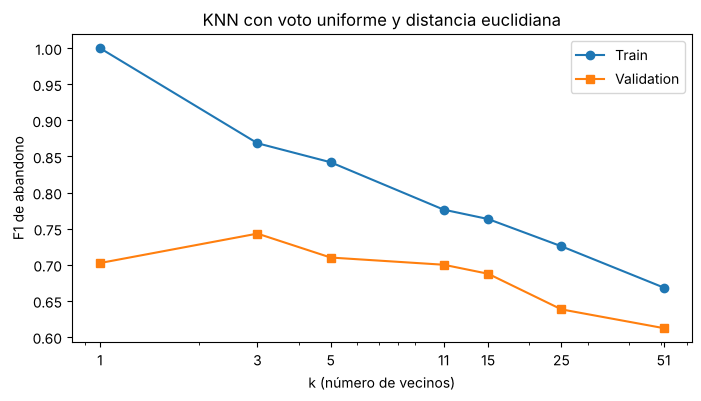

In [50]:
d = rejilla_knn[(rejilla_knn["voto"] == "uniform") & (rejilla_knn["distancia"] == "euclidiana")]
plt.figure(figsize=(8, 4))
plt.plot(d["k"], d["f1_train"], marker="o", label="Train"); plt.plot(d["k"], d["f1_val"], marker="s", label="Validation")
plt.xscale("log"); plt.xticks(d["k"], d["k"]); plt.xlabel("k (número de vecinos)"); plt.ylabel("F1 de abandono")
plt.title("KNN con voto uniforme y distancia euclidiana"); plt.legend(); plt.show()

**Cómo leer la curva.** Con k = 1 el F1 de Train es 1 (cada cliente es su propio vecino) y Validation es mucho menor: memoriza. Al subir k, Train baja y se acerca a Validation; con k muy grande ambos bajan porque los muchos clientes que se quedan ganan las votaciones.

**Cuidado con `weights="distance"`:** en Train, cada cliente es su propio vecino a distancia 0 y su voto pesa infinito, así que el F1 de Train sale siempre 1. Esa brecha no indica nada. Por eso elegimos la combinación con **mejor F1 en Validation entre las que tienen una brecha menor a 0,15**.

In [51]:
mejor_knn = rejilla_knn[rejilla_knn["brecha"] < 0.15].sort_values("f1_val", ascending=False).iloc[0]   # descarta las que memorizan
KNN_PARAMS = {"n_neighbors": int(mejor_knn["k"]), "weights": mejor_knn["voto"], "p": 2 if mejor_knn["distancia"] == "euclidiana" else 1}
print("Mejor configuración en Validation:", KNN_PARAMS)

Mejor configuración en Validation: {'n_neighbors': 3, 'weights': 'uniform', 'p': 1}


## B.10 El desbalance en KNN: sobremuestreo

KNN no tiene `class_weight`. Si repetimos abandonos en Train hasta igualar a los que se quedan, habrá más vecinos «abandonó» y KNN avisará más.

In [52]:
entreno_ch = X_train_ch.assign(y=y_train_ch.values)
se_queda, abandona = entreno_ch[entreno_ch["y"] == 0], entreno_ch[entreno_ch["y"] == 1]
sobre_ch = pd.concat([se_queda, resample(abandona, replace=True, n_samples=len(se_queda), random_state=42)])
print("Train original:", len(entreno_ch), "filas,", f"{entreno_ch['y'].mean():.0%}", "abandonos | Sobremuestreado:", len(sobre_ch), "filas,", f"{sobre_ch['y'].mean():.0%}")
knn_final = Pipeline([("escalar", StandardScaler()), ("knn", KNeighborsClassifier(**KNN_PARAMS))]).fit(X_train_ch, y_train_ch)
knn_sobre = Pipeline([("escalar", StandardScaler()), ("knn", KNeighborsClassifier(**KNN_PARAMS))]).fit(sobre_ch[FEAT_KNN], sobre_ch["y"])
res_knn = evaluar(knn_final, f"KNN elegido {KNN_PARAMS}", X_train_ch, y_train_ch, X_val_ch, y_val_ch)
res_knn_sobre = evaluar(knn_sobre, "KNN elegido + sobremuestreo", X_train_ch, y_train_ch, X_val_ch, y_val_ch)
tabla([res_base_ch, res_knn_simple, res_knn, res_knn_sobre])

Train original: 7088 filas, 16% abandonos | Sobremuestreado: 11898 filas, 50%


,f1_train,f1_val,brecha,precision_val,recall_val,accuracy_val,alertas_val
modelo,,,,,,,
Línea base: siempre «se queda»,0.000,0.000,0.000,0.000,0.000,0.839,0
"KNN simple (k=5, estandarizado)",0.842,0.710,0.132,0.818,0.627,0.918,187
"KNN elegido {'n_neighbors': 3, 'weights': 'uniform', 'p': 1}",0.877,0.745,0.131,0.837,0.672,0.926,196
KNN elegido + sobremuestreo,0.904,0.733,0.170,0.681,0.795,0.907,285


## B.11 Modelo final de BankChurners (con KNN)

**Interpretación.** El KNN elegido supera ampliamente a la línea base y mejora al KNN por defecto con una brecha parecida. Con pocos vecinos, la distancia Manhattan funciona algo mejor que la euclidiana en estos datos. El sobremuestreo vuelve a mover el intercambio: más Recall, menos Precision. Si el banco puede contactar a muchos clientes a bajo costo, convendría la versión sobremuestreada; si cada llamada es cara, el KNN sin balancear. En la Parte D veremos si otro algoritmo le gana en este mismo dataset.

# Parte C · Credit Risk: SVM, una frontera entre préstamos

**El problema.** Estimar si un préstamo aprobado caerá en impago, con la información de la solicitud.

**El dataset.** Credit Risk Dataset (Kaggle): 32 581 préstamos con datos del solicitante (edad, ingreso, vivienda, antigüedad laboral), del préstamo (propósito, grado de riesgo, monto, tasa) y su historial crediticio. El 21,8 % cayó en impago. Revisa la licencia en Kaggle antes de usarlo fuera de clase.

**Por qué SVM.** Pagados e impagos se separan bastante bien con la tasa y la proporción del ingreso que representa el préstamo, así que se puede **dibujar la frontera** que traza SVM.

## C.1 Mirar los datos

In [53]:
credit = pd.read_csv(ARCHIVO_CREDIT)
print("Filas y columnas:", credit.shape)
credit.head()

Filas y columnas: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [54]:
credit.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


| Columna | Qué es |
|---|---|
| `person_age`, `person_income` | Edad e ingreso anual |
| `person_home_ownership` | Vivienda: `RENT` (arrienda), `OWN` (propia), `MORTGAGE` (hipotecada), `OTHER` — **texto** |
| `person_emp_length` | Años de antigüedad laboral |
| `loan_intent` | Propósito del préstamo (educación, salud, negocio…) — **texto** |
| `loan_grade` | Grado de riesgo asignado por la entidad, de A (mejor) a G — **texto** |
| `loan_amnt`, `loan_int_rate` | Monto y tasa de interés |
| `loan_percent_income` | Monto del préstamo / ingreso |
| `cb_person_default_on_file` | ¿Tuvo un impago antes? Y / N — **texto** |
| `cb_person_cred_hist_length` | Años de historial crediticio |
| `loan_status` | **Respuesta**: 1 = impago, 0 = pagado |

In [55]:
credit.describe().round(2)

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.00,32581.00,31686.00,32581.00,29465.00,32581.00,32581.00,32581.00
mean,27.73,66074.85,4.79,9589.37,11.01,0.22,0.17,5.80
std,6.35,61983.12,4.14,6322.09,3.24,0.41,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38500.00,2.00,5000.00,7.90,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.00,0.15,4.00
75%,30.00,79200.00,7.00,12200.00,13.47,0.00,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,1.00,0.83,30.00


**Lee el resumen.** Hay valores imposibles: una edad máxima de 144 años y una antigüedad laboral de 123 años. También faltan valores en `person_emp_length` y `loan_int_rate` (el `count` es menor).

## C.2 Entender y graficar

Proporción de impago: 21.8 %


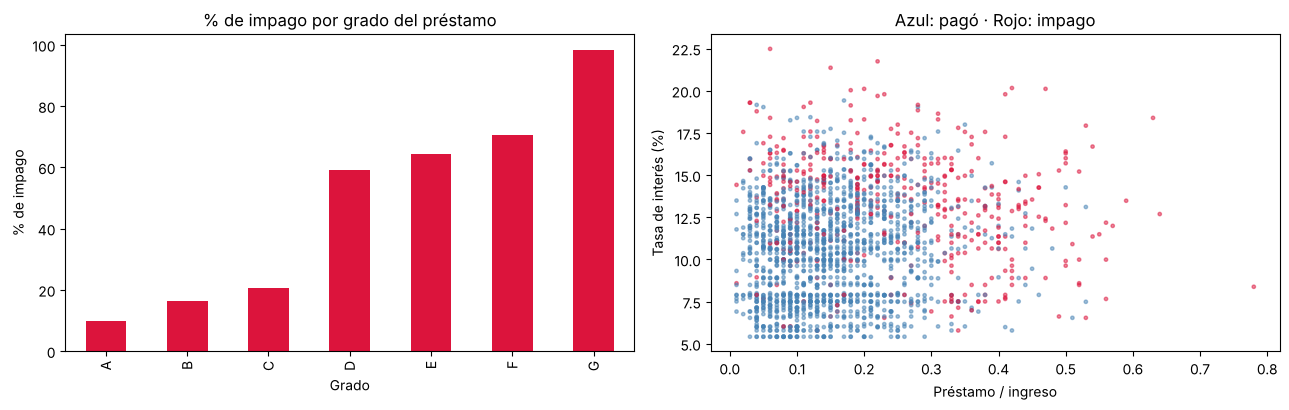

In [56]:
print("Proporción de impago:", round(credit["loan_status"].mean() * 100, 1), "%")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
(credit.groupby("loan_grade")["loan_status"].mean() * 100).plot(kind="bar", color="crimson", ax=ax[0])
ax[0].set(title="% de impago por grado del préstamo", xlabel="Grado", ylabel="% de impago")
muestra_graf = credit.dropna().sample(2000, random_state=1)
ax[1].scatter(muestra_graf["loan_percent_income"], muestra_graf["loan_int_rate"], s=6, alpha=0.5,
              c=muestra_graf["loan_status"].map({0: "steelblue", 1: "crimson"}))
ax[1].set(title="Azul: pagó · Rojo: impago", xlabel="Préstamo / ingreso", ylabel="Tasa de interés (%)")
plt.tight_layout(); plt.show()

**Interpretación.** El impago sube con el grado: del 10 % en A a casi todos en G. En el gráfico, los impagos (rojo) se concentran a la derecha (préstamo grande frente al ingreso) y arriba (tasa alta): hay una frontera bastante clara.

## C.3 Limpiar y preparar, paso a paso

**Paso 1: errores de registro y duplicados.**

In [57]:
print("Filas al inicio:", len(credit))
print("Edad > 100:", int((credit["person_age"] > 100).sum()), "| Antigüedad > 60 años:", int((credit["person_emp_length"] > 60).sum()),
      "| Duplicados:", int(credit.duplicated().sum()))
credit = credit[(credit["person_age"] <= 100) & ~(credit["person_emp_length"] > 60)]   # quitar valores imposibles
credit = credit.drop_duplicates()                                                       # quitar filas repetidas
print("Filas después de limpiar:", len(credit))

Filas al inicio: 32581
Edad > 100: 5 | Antigüedad > 60 años: 2 | Duplicados: 165
Filas después de limpiar: 32409


**Paso 2: una muestra.** SVM se vuelve lento con muchas filas. Tomamos una muestra **estratificada** de 12 000 préstamos (conserva el 21,8 % de impagos) y la dividimos 70 / 15 / 15.

In [58]:
muestra_cr = credit.groupby("loan_status", group_keys=False).sample(frac=12000 / len(credit), random_state=42)
y_cr = muestra_cr["loan_status"]
X_cr = muestra_cr.drop(columns=["loan_status"])
X_train_cr, X_rest_cr, y_train_cr, y_rest_cr = train_test_split(X_cr, y_cr, test_size=0.30, random_state=42, stratify=y_cr)
X_val_cr, X_test_cr, y_val_cr, y_test_cr = train_test_split(X_rest_cr, y_rest_cr, test_size=0.50, random_state=42, stratify=y_rest_cr)
for nombre, yy in [("Train", y_train_cr), ("Validation", y_val_cr), ("Test", y_test_cr)]:
    print(f"{nombre:10s}: {len(yy):5d} préstamos, {yy.mean():.1%} impagos")
NUM_CR = X_cr.select_dtypes(include="number").columns.tolist()     # columnas numéricas
CAT_CR = X_cr.select_dtypes(exclude="number").columns.tolist()     # columnas de texto
print("Numéricas:", NUM_CR); print("Texto:", CAT_CR)

Train     :  8400 préstamos, 21.9% impagos
Validation:  1800 préstamos, 21.9% impagos
Test      :  1800 préstamos, 21.8% impagos
Numéricas: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Texto: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


**Paso 3: rellenar faltantes (imputar) con la mediana de Train.** No eliminamos filas: rellenamos con la mediana, **calculada solo con Train**.

In [59]:
mediana_tasa = X_train_cr["loan_int_rate"].median()                  # mediana aprendida en Train
print("Faltantes de tasa en Train:", int(X_train_cr["loan_int_rate"].isna().sum()), "| se rellenan con", mediana_tasa)
imputador = SimpleImputer(strategy="median").fit(X_train_cr[NUM_CR])  # lo mismo para todas las numéricas
print("Medianas aprendidas:", dict(zip(NUM_CR, imputador.statistics_.round(2))))

Faltantes de tasa en Train: 757 | se rellenan con 10.99
Medianas aprendidas: {'person_age': np.float64(26.0), 'person_income': np.float64(56000.0), 'person_emp_length': np.float64(4.0), 'loan_amnt': np.float64(8000.0), 'loan_int_rate': np.float64(10.99), 'loan_percent_income': np.float64(0.15), 'cb_person_cred_hist_length': np.float64(4.0)}


**Paso 4: convertir el texto en números (One-Hot).** SVM solo entiende números. No podemos poner A = 1, B = 2…: eso diría que «G es siete veces A». **One-Hot** crea una columna 0/1 por cada categoría. Mira el antes y el después:

In [60]:
print("Antes:"); print(X_train_cr[["person_home_ownership"]].head(4))
onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(X_train_cr[["person_home_ownership"]])
print("\nDespués de One-Hot:")
print(pd.DataFrame(onehot.transform(X_train_cr[["person_home_ownership"]].head(4)), columns=onehot.get_feature_names_out()).astype(int))

Antes:
      person_home_ownership
24751                  RENT
24593              MORTGAGE
16517                  RENT
22608                  RENT

Después de One-Hot:
   person_home_ownership_MORTGAGE  person_home_ownership_OTHER  person_home_ownership_OWN  person_home_ownership_RENT
0                               0                            0                          0                           1
1                               1                            0                          0                           0
2                               0                            0                          0                           1
3                               0                            0                          0                           1


`handle_unknown="ignore"`: si en Validation aparece una categoría que no estaba en Train, se deja en ceros en lugar de dar error.

**Paso 5: escalar las numéricas.** Igual que en KNN, SVM mide distancias: el ingreso (decenas de miles) no debe aplastar a la tasa (unidades). Usamos `StandardScaler`.

**Paso 6: juntar todo con `ColumnTransformer`.** Aplica una preparación a las numéricas (imputar y escalar) y otra al texto (imputar y One-Hot), y pega el resultado. Todo se aprende con Train.

In [61]:
prep_cr = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]), NUM_CR),
    ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT_CR)])
prep_cr.fit(X_train_cr)                                                    # aprende medianas, medias, desviaciones y categorías
tabla_lista = pd.DataFrame(prep_cr.transform(X_train_cr), columns=prep_cr.get_feature_names_out())
print("Columnas antes:", X_train_cr.shape[1], "| columnas después:", tabla_lista.shape[1])
tabla_lista.head(3).round(2)

Columnas antes: 11 | columnas después: 26


,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,cat__person_home_ownership_RENT,cat__loan_intent_DEBTCONSOLIDATION,cat__loan_intent_EDUCATION,cat__loan_intent_HOMEIMPROVEMENT,cat__loan_intent_MEDICAL,cat__loan_intent_PERSONAL,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,1.02,0.28,0.30,0.07,-0.36,-0.37,0.29,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.04,0.18,-0.70,0.87,1.19,0.29,0.29,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-0.93,-0.41,-1.19,-0.89,-0.01,-0.75,-0.70,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


**Lee la tabla.** Así llegan los datos a SVM: las numéricas estandarizadas (`num__…`) y una columna 0/1 por categoría (`cat__…`). De 11 columnas pasamos a 26.

## C.4 La línea base

In [62]:
base_cr = DummyClassifier(strategy="most_frequent").fit(X_train_cr, y_train_cr)
res_base_cr = evaluar(base_cr, "Línea base: siempre «paga»", X_train_cr, y_train_cr, X_val_cr, y_val_cr)
tabla([res_base_cr])

,f1_train,f1_val,brecha,precision_val,recall_val,accuracy_val,alertas_val
modelo,,,,,,,
Línea base: siempre «paga»,0.0,0.0,0.0,0.0,0.0,0.781,0


## C.5 SVM a mano

**La idea.** SVM traza la frontera que deja la **calle más ancha** posible entre las dos clases. Los puntos que tocan la calle son los **vectores de soporte**.

**Ejemplo con una variable** (cuota / ingreso): pagados en 0,10, 0,15 y 0,20; impagos en 0,40, 0,45 y 0,55. Cualquier corte entre 0,20 y 0,40 separa perfecto, pero SVM elige el punto medio, **0,30**, porque deja 0,10 de margen a cada lado. Vectores de soporte: 0,20 y 0,40.

**La multa C.** Si aparece un impago «raro» en 0,24, hay dos opciones: **A**, calle ancha (de 0,20 a 0,40) aceptando ese error, o **B**, calle estrecha (de 0,20 a 0,24) sin errores. SVM minimiza $\text{costo} = 2/\text{ancho}^2 + C\times\text{multas}$, donde la multa mide cuánto invade el punto la calle (aquí 1,6).

**Fronteras curvas (kernel).** Si los impagos están en los dos extremos de una variable $x$, ninguna recta los separa. Agregando $x^2$ sí se puede. El kernel RBF hace eso automáticamente.

In [63]:
# El costo de cada opción según C
for C_ in [1, 100, 1000]:
    costo_a = 2 / 0.20 ** 2 + C_ * 1.6      # calle ancha, con multa
    costo_b = 2 / 0.04 ** 2 + C_ * 0        # calle estrecha, sin multa
    print(f"C = {C_:5d}: A = {costo_a:7.1f} | B = {costo_b:7.1f} → gana {'A (ancha)' if costo_a < costo_b else 'B (estrecha)'}")

C =     1: A =    51.6 | B =  1250.0 → gana A (ancha)
C =   100: A =   210.0 | B =  1250.0 → gana A (ancha)
C =  1000: A =  1650.0 | B =  1250.0 → gana B (estrecha)


Con C pequeño las multas son baratas y gana la calle ancha; con C grande gana la estrecha, que persigue cada punto. **C controla qué tanto se ajusta el modelo a Train.**

## C.6 El modelo más simple con scikit-learn

Con solo dos variables, para poder dibujar la frontera. Paso a paso: imputar, escalar y SVM con sus valores por defecto (`kernel="rbf"`, `C=1`).

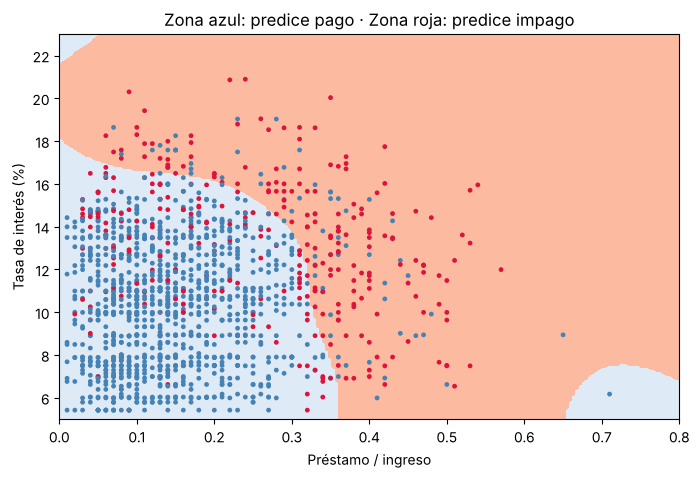

In [64]:
DOS_CR = ["loan_percent_income", "loan_int_rate"]
svm_simple = Pipeline([("imputar", SimpleImputer(strategy="median")),   # 1) rellenar la tasa faltante
                       ("escalar", StandardScaler()),                    # 2) estandarizar
                       ("svm", SVC())])                                  # 3) SVM con valores por defecto
svm_simple.fit(X_train_cr[DOS_CR], y_train_cr)                           # entrenar con Train
res_svm_simple = evaluar(svm_simple, "SVM simple (2 variables, por defecto)", X_train_cr[DOS_CR], y_train_cr, X_val_cr[DOS_CR], y_val_cr)

gx, gy = np.meshgrid(np.linspace(0, 0.8, 200), np.linspace(5, 23, 200))           # una malla de puntos para pintar las zonas
zona = svm_simple.predict(pd.DataFrame({"loan_percent_income": gx.ravel(), "loan_int_rate": gy.ravel()})).reshape(gx.shape)
puntos = X_train_cr[DOS_CR].assign(y=y_train_cr).dropna().sample(1500, random_state=1)
plt.figure(figsize=(8, 5))
plt.contourf(gx, gy, zona, levels=[-0.5, 0.5, 1.5], colors=["#deebf7", "#fcbba1"])
plt.scatter(puntos["loan_percent_income"], puntos["loan_int_rate"], c=puntos["y"].map({0: "steelblue", 1: "crimson"}), s=6)
plt.xlabel("Préstamo / ingreso"); plt.ylabel("Tasa de interés (%)"); plt.title("Zona azul: predice pago · Zona roja: predice impago"); plt.show()

## C.7 Las métricas: a mano y con scikit-learn, en Train y en Validation

In [65]:
pred = svm_simple.predict(X_val_cr[DOS_CR])
vn, fp, fn, vp = confusion_matrix(y_val_cr, pred, labels=[0, 1]).ravel()
print(f"VN={vn}  FP={fp}  FN={fn}  VP={vp}")
print(f"A mano: Precision = {vp}/({vp}+{fp}) = {vp / (vp + fp):.3f} | Recall = {vp}/({vp}+{fn}) = {vp / (vp + fn):.3f} | F1 = {2 * vp / (2 * vp + fp + fn):.3f}")
print("Con scikit-learn:", {k: round(v, 3) for k, v in metricas(y_val_cr, pred).items()})
tabla([res_base_cr, res_svm_simple])

VN=1324  FP=82  FN=223  VP=171
A mano: Precision = 171/(171+82) = 0.676 | Recall = 171/(171+223) = 0.434 | F1 = 0.529
Con scikit-learn: {'accuracy': 0.831, 'precision': 0.676, 'recall': 0.434, 'f1': 0.529}


,f1_train,f1_val,brecha,precision_val,recall_val,accuracy_val,alertas_val
modelo,,,,,,,
Línea base: siempre «paga»,0.000,0.000,0.000,0.000,0.000,0.781,0
"SVM simple (2 variables, por defecto)",0.541,0.529,0.012,0.676,0.434,0.831,253


**Interpretación.** Con solo dos variables, la SVM ya supera a la línea base y no memoriza (Train ≈ Validation). Para mejorar, usaremos **todas** las variables y ajustaremos sus hiperparámetros.

## C.8 Los hiperparámetros de SVM, uno por uno

| Hiperparámetro | Qué controla | Efecto | Valor por defecto |
|---|---|---|---|
| `C` | La multa por cada punto del lado equivocado o dentro de la calle | C pequeño: calle ancha, tolera errores. C grande: calle estrecha, persigue cada punto (puede memorizar) | 1 |
| `kernel` | La forma de la frontera: `"linear"` (recta) o `"rbf"` (curva) | RBF se adapta a fronteras curvas | `"rbf"` |
| `gamma` | Solo con RBF: qué tan lejos llega la influencia de cada punto | gamma grande: frontera muy ondulada (memoriza). Pequeño: frontera suave | `"scale"` (automático) |
| `class_weight` | Peso de cada clase; `"balanced"` da más peso a la clase rara | Más alertas: sube Recall, baja Precision | `None` |

## C.9 Probar combinaciones con un `for`

Primero `C` con todas las variables (kernel RBF):

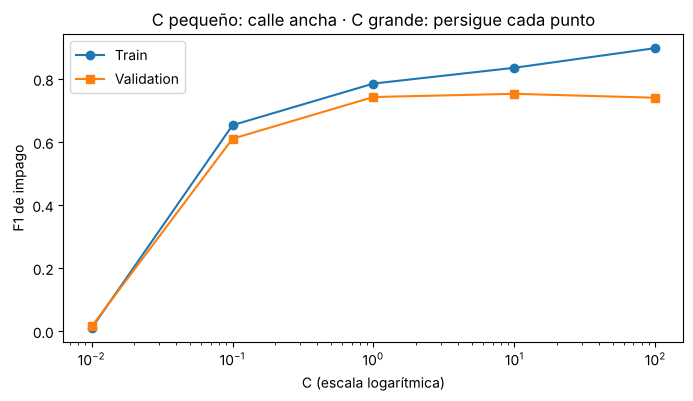

,f1_train,f1_val,brecha,precision_val,recall_val,accuracy_val,alertas_val,C,vectores_soporte
modelo,,,,,,,,,
"RBF, C=0.01",0.010,0.015,-0.005,1.000,0.008,0.783,3,0.01,3699
"RBF, C=0.1",0.653,0.611,0.043,0.873,0.470,0.869,212,0.10,3199
"RBF, C=1",0.785,0.743,0.043,0.911,0.627,0.905,271,1.00,2629
"RBF, C=10",0.836,0.753,0.083,0.895,0.650,0.907,286,10.00,2361
"RBF, C=100",0.898,0.741,0.157,0.828,0.670,0.897,319,100.00,2293


In [66]:
filas = []
for valor_c in [0.01, 0.1, 1, 10, 100]:
    m = Pipeline([("prep", prep_cr), ("svm", SVC(C=valor_c))]).fit(X_train_cr, y_train_cr)
    fila = evaluar(m, f"RBF, C={valor_c}", X_train_cr, y_train_cr, X_val_cr, y_val_cr)
    fila.update({"C": valor_c, "vectores_soporte": int(m.named_steps["svm"].n_support_.sum())})
    filas.append(fila)
rejilla_c = pd.DataFrame(filas)
plt.figure(figsize=(8, 4))
plt.plot(rejilla_c["C"], rejilla_c["f1_train"], marker="o", label="Train"); plt.plot(rejilla_c["C"], rejilla_c["f1_val"], marker="s", label="Validation")
plt.xscale("log"); plt.xlabel("C (escala logarítmica)"); plt.ylabel("F1 de impago"); plt.legend(); plt.title("C pequeño: calle ancha · C grande: persigue cada punto"); plt.show()
rejilla_c.set_index("modelo").round(3)

**Cómo leer la curva.** Con C muy pequeño la SVM es demasiado tolerante y casi no detecta impagos. Al subir C, Train y Validation mejoran juntos. Con C muy grande Train sigue subiendo y Validation se estanca o baja: la brecha crece, empieza a memorizar. Los **vectores de soporte** disminuyen al subir C: la calle se estrecha y menos puntos la tocan.

Ahora una rejilla con `kernel`, `C` y `class_weight`, y otra con `gamma`:

In [67]:
filas = []
for kernel in ["linear", "rbf"]:
    for valor_c in [0.5, 1, 5]:
        for peso in [None, "balanced"]:
            m = Pipeline([("prep", prep_cr), ("svm", SVC(kernel=kernel, C=valor_c, class_weight=peso))]).fit(X_train_cr, y_train_cr)
            fila = evaluar(m, f"{kernel}, C={valor_c}, peso={peso}", X_train_cr, y_train_cr, X_val_cr, y_val_cr)
            fila.update({"kernel": kernel, "C": valor_c, "class_weight": peso})
            filas.append(fila)
rejilla_svm = pd.DataFrame(filas)
rejilla_svm.sort_values("f1_val", ascending=False).set_index("modelo").round(3)

,f1_train,f1_val,brecha,precision_val,recall_val,accuracy_val,alertas_val,kernel,C,class_weight
modelo,,,,,,,,,,
"rbf, C=5, peso=None",0.820,0.763,0.056,0.915,0.655,0.911,282,rbf,5.0,NaN
"rbf, C=1, peso=None",0.785,0.743,0.043,0.911,0.627,0.905,271,rbf,1.0,NaN
"rbf, C=5, peso=balanced",0.812,0.719,0.093,0.705,0.734,0.874,410,rbf,5.0,balanced
"rbf, C=1, peso=balanced",0.759,0.714,0.045,0.678,0.754,0.868,438,rbf,1.0,balanced
"rbf, C=0.5, peso=None",0.753,0.706,0.046,0.888,0.586,0.893,260,rbf,0.5,NaN
"rbf, C=0.5, peso=balanced",0.736,0.704,0.033,0.656,0.759,0.860,456,rbf,0.5,balanced
"linear, C=5, peso=balanced",0.648,0.635,0.013,0.563,0.728,0.817,510,linear,5.0,balanced
"linear, C=1, peso=balanced",0.648,0.631,0.018,0.559,0.723,0.814,510,linear,1.0,balanced
"linear, C=0.5, peso=balanced",0.648,0.630,0.018,0.558,0.723,0.814,511,linear,0.5,balanced


In [68]:
filas = []
for g in [0.01, 0.1, "scale", 1, 10]:
    m = Pipeline([("prep", prep_cr), ("svm", SVC(C=1, gamma=g))]).fit(X_train_cr, y_train_cr)
    filas.append(evaluar(m, f"RBF, C=1, gamma={g}", X_train_cr, y_train_cr, X_val_cr, y_val_cr))
tabla(filas)

,f1_train,f1_val,brecha,precision_val,recall_val,accuracy_val,alertas_val
modelo,,,,,,,
"RBF, C=1, gamma=0.01",0.651,0.633,0.018,0.828,0.513,0.870,244
"RBF, C=1, gamma=0.1",0.787,0.745,0.042,0.912,0.629,0.906,272
"RBF, C=1, gamma=scale",0.785,0.743,0.043,0.911,0.627,0.905,271
"RBF, C=1, gamma=1",0.905,0.572,0.333,0.926,0.414,0.864,176
"RBF, C=1, gamma=10",0.998,0.005,0.993,1.000,0.003,0.782,1


**Lee las tablas.** La frontera curva (RBF) supera a la recta. `class_weight="balanced"` sube el Recall y baja la Precision. Con `gamma` muy grande (10) el F1 de Train se dispara y el de Validation cae: cada punto de Train tiene su propia «isla» y la SVM memoriza.

## C.10 Modelo final de Credit Risk (con SVM)

In [69]:
mejor_svm = rejilla_svm.sort_values("f1_val", ascending=False).iloc[0]
peso = None if pd.isna(mejor_svm["class_weight"]) else mejor_svm["class_weight"]   # pandas guarda None como NaN
SVM_PARAMS = {"kernel": mejor_svm["kernel"], "C": float(mejor_svm["C"]), "class_weight": peso}
svm_final = Pipeline([("prep", prep_cr), ("svm", SVC(**SVM_PARAMS))]).fit(X_train_cr, y_train_cr)
res_svm = evaluar(svm_final, f"SVM elegida {SVM_PARAMS}", X_train_cr, y_train_cr, X_val_cr, y_val_cr)
tabla([res_base_cr, res_svm_simple, res_svm])

,f1_train,f1_val,brecha,precision_val,recall_val,accuracy_val,alertas_val
modelo,,,,,,,
Línea base: siempre «paga»,0.000,0.000,0.000,0.000,0.000,0.781,0
"SVM simple (2 variables, por defecto)",0.541,0.529,0.012,0.676,0.434,0.831,253
"SVM elegida {'kernel': 'rbf', 'C': 5.0, 'class_weight': None}",0.820,0.763,0.056,0.915,0.655,0.911,282


**Interpretación.** La SVM con todas las variables supera claramente a la versión de dos variables y a la línea base. SVM funciona mucho mejor cuando las clases están **bien separadas**, como aquí: con dos variables la frontera deja muchos préstamos del lado equivocado; con todas, la separación es más clara. ¿Le gana otro algoritmo en este dataset? Lo vemos en la Parte D.

# Parte D · Todos los modelos en todos los datasets: ¿cuál escoger en cada caso?

Hasta ahora explicamos cada algoritmo con el dataset que mejor lo ilustra. Pero en la práctica **no sabemos de antemano qué algoritmo funcionará mejor**: hay que probarlos todos en los mismos datos y escoger con la métrica. Haremos exactamente eso:

1. Para cada dataset preparamos los datos **una sola vez** (las mismas divisiones de las partes A, B y C).
2. Para cada modelo probamos una rejilla pequeña de hiperparámetros con un `for` y nos quedamos con la mejor configuración **en Validation**.
3. Comparamos los cinco modelos (línea base, árbol, Random Forest, KNN y SVM) por **F1 en Validation**, revisando también la brecha con Train.
4. Escogemos un ganador por dataset y lo evaluamos **una sola vez en Test**.

**Preparación de cada dataset para todos los modelos:**

| Dataset | Variables | Preparación común |
|---|---|---|
| PaySim | `transfer_o_retiro`, `amount`, `hora` | Logaritmo del monto (muy asimétrico) y estandarización. A los árboles no les afecta; a KNN y SVM sí les ayuda |
| BankChurners | Las 11 numéricas de la Parte B | Estandarización |
| Credit Risk | Todas | Imputar, estandarizar y One-Hot (el `prep_cr` de la Parte C) |

SVM es lenta con muchas filas: en PaySim la entrenamos con una muestra estratificada de 12 000 transacciones de Train (las demás usan Train completo). Todas se miden en la **misma** Validation.

In [70]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.base import clone      # copia "en blanco" de un objeto de scikit-learn

# --- PaySim: logaritmo del monto + estandarización (como un paso del Pipeline) ---
log_monto = ColumnTransformer([("log", FunctionTransformer(np.log1p), ["amount"])], remainder="passthrough")
prep_pay = Pipeline([("log", log_monto), ("escalar", StandardScaler())])
# Muestra estratificada de Train para SVM (solo en PaySim)
X_tr_pay_svm, _, y_tr_pay_svm, _ = train_test_split(X_train_pay, y_train_pay, train_size=12000, random_state=42, stratify=y_train_pay)

DATASETS = {
    "PaySim (fraude)":        dict(Xtr=X_train_pay, ytr=y_train_pay, Xva=X_val_pay, yva=y_val_pay, Xte=X_test_pay, yte=y_test_pay,
                                   prep=prep_pay, Xtr_svm=X_tr_pay_svm, ytr_svm=y_tr_pay_svm),
    "BankChurners (abandono)": dict(Xtr=X_train_ch, ytr=y_train_ch, Xva=X_val_ch, yva=y_val_ch, Xte=X_test_ch, yte=y_test_ch,
                                   prep=StandardScaler(), Xtr_svm=X_train_ch, ytr_svm=y_train_ch),
    "Credit Risk (impago)":   dict(Xtr=X_train_cr, ytr=y_train_cr, Xva=X_val_cr, yva=y_val_cr, Xte=X_test_cr, yte=y_test_cr,
                                   prep=prep_cr, Xtr_svm=X_train_cr, ytr_svm=y_train_cr),
}

# Rejillas pequeñas de hiperparámetros para cada modelo
REJILLAS = {
    "Línea base": [("siempre la clase mayoritaria", lambda: DummyClassifier(strategy="most_frequent"))],
    "Árbol": [(f"prof={d}, hoja=30, peso={w}", lambda d=d, w=w: DecisionTreeClassifier(max_depth=d, min_samples_leaf=30, class_weight=w, random_state=42))
              for d in [3, 5, 8] for w in [None, "balanced"]],
    "Random Forest": [(f"200 árboles, prof={d}, peso={w}", lambda d=d, w=w: RandomForestClassifier(n_estimators=200, max_depth=d, min_samples_leaf=5,
                                                                                             class_weight=w, random_state=42, n_jobs=-1))
                      for d in [8, 12] for w in [None, "balanced"]],
    "KNN": [(f"k={k}, Manhattan", lambda k=k: KNeighborsClassifier(n_neighbors=k, p=1)) for k in [5, 15, 31]],
    "SVM": [(f"RBF, C={c}, peso={w}", lambda c=c, w=w: SVC(C=c, class_weight=w)) for c in [0.5, 1, 5] for w in [None, "balanced"]],
}
print("Configuraciones por dataset:", sum(len(v) for v in REJILLAS.values()))

Configuraciones por dataset: 20


In [71]:
import time
todas = []          # todas las configuraciones probadas
mejores = {}        # el mejor modelo entrenado de cada (dataset, algoritmo)
inicio = time.time()
for nombre_ds, ds in DATASETS.items():
    for algoritmo, rejilla in REJILLAS.items():
        for config, crear in rejilla:
            modelo = Pipeline([("prep", clone(ds["prep"])), ("modelo", crear())])    # clone: una copia nueva de la preparación
            if algoritmo == "SVM":
                modelo.fit(ds["Xtr_svm"], ds["ytr_svm"])                              # SVM: muestra de Train en PaySim
            else:
                modelo.fit(ds["Xtr"], ds["ytr"])
            fila = evaluar(modelo, config, ds["Xtr"], ds["ytr"], ds["Xva"], ds["yva"])
            fila.update({"dataset": nombre_ds, "algoritmo": algoritmo})
            todas.append(fila)
            clave = (nombre_ds, algoritmo)
            if clave not in mejores or fila["f1_val"] > mejores[clave][0]["f1_val"]:
                mejores[clave] = (fila, modelo)
print(f"Listo: {len(todas)} modelos entrenados en {time.time() - inicio:.0f} segundos")

Listo: 60 modelos entrenados en 126 segundos


In [72]:
resumen_mejores = pd.DataFrame([f for f, _ in mejores.values()])
resumen_mejores = resumen_mejores[["dataset", "algoritmo", "modelo", "f1_train", "f1_val", "brecha", "precision_val", "recall_val", "alertas_val"]]
resumen_mejores = resumen_mejores.rename(columns={"modelo": "mejor configuración"}).round(3)
resumen_mejores

,dataset,algoritmo,mejor configuración,f1_train,f1_val,brecha,precision_val,recall_val,alertas_val
0,PaySim (fraude),Línea base,siempre la clase mayoritaria,0.000,0.000,0.000,0.000,0.000,0
1,PaySim (fraude),Árbol,"prof=3, hoja=30, peso=None",0.597,0.637,-0.040,0.798,0.530,852
2,PaySim (fraude),Random Forest,"200 árboles, prof=12, peso=None",0.657,0.632,0.025,0.813,0.517,815
3,PaySim (fraude),KNN,"k=15, Manhattan",0.627,0.627,-0.001,0.784,0.523,856
4,PaySim (fraude),SVM,"RBF, C=5, peso=None",0.545,0.596,-0.052,0.893,0.447,643
5,BankChurners (abandono),Línea base,siempre la clase mayoritaria,0.000,0.000,0.000,0.000,0.000,0
6,BankChurners (abandono),Árbol,"prof=5, hoja=30, peso=None",0.800,0.779,0.021,0.771,0.787,249
7,BankChurners (abandono),Random Forest,"200 árboles, prof=12, peso=balanced",0.930,0.863,0.067,0.805,0.930,282
8,BankChurners (abandono),KNN,"k=5, Manhattan",0.849,0.738,0.110,0.859,0.648,184
9,BankChurners (abandono),SVM,"RBF, C=5, peso=balanced",0.862,0.802,0.060,0.731,0.889,297


F1 en Validation (mejor configuración de cada algoritmo):
dataset        BankChurners (abandono)  Credit Risk (impago)  PaySim (fraude)
algoritmo                                                                    
Línea base                       0.000                 0.000            0.000
Árbol                            0.779                 0.742            0.637
Random Forest                    0.863                 0.769            0.632
KNN                              0.738                 0.672            0.627
SVM                              0.802                 0.763            0.596


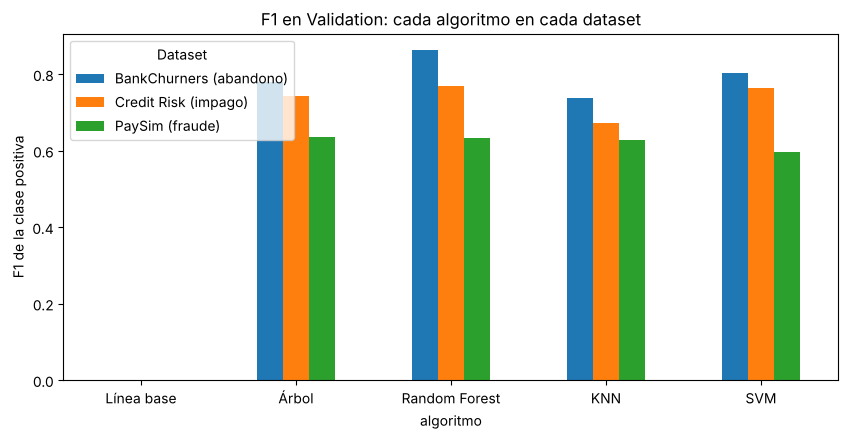

In [73]:
f1_tabla = resumen_mejores.pivot(index="algoritmo", columns="dataset", values="f1_val").loc[["Línea base", "Árbol", "Random Forest", "KNN", "SVM"]]
print("F1 en Validation (mejor configuración de cada algoritmo):")
print(f1_tabla.round(3))
f1_tabla.plot(kind="bar", figsize=(10, 4.5), rot=0, title="F1 en Validation: cada algoritmo en cada dataset")
plt.ylabel("F1 de la clase positiva"); plt.legend(title="Dataset"); plt.show()

### Escoger un modelo para cada dataset

Regla: el **mayor F1 en Validation**, siempre que la brecha con Train sea razonable (menor a 0,10). Si dos modelos quedan casi empatados, conviene preferir el más simple de explicar.

In [74]:
ganadores = {}
for nombre_ds in DATASETS:
    candidatos = resumen_mejores[(resumen_mejores["dataset"] == nombre_ds) & (resumen_mejores["brecha"] < 0.10)]
    fila = candidatos.sort_values("f1_val", ascending=False).iloc[0]
    ganadores[nombre_ds] = fila["algoritmo"]
    print(f"{nombre_ds:25s} → gana {fila['algoritmo']:14s} ({fila['mejor configuración']}) con F1 Validation = {fila['f1_val']:.3f}")

PaySim (fraude)           → gana Árbol          (prof=3, hoja=30, peso=None) con F1 Validation = 0.637
BankChurners (abandono)   → gana Random Forest  (200 árboles, prof=12, peso=balanced) con F1 Validation = 0.863
Credit Risk (impago)      → gana Random Forest  (200 árboles, prof=12, peso=None) con F1 Validation = 0.769


### El examen final: Test, una sola vez

Solo ahora, con el modelo de cada dataset ya escogido, abrimos Test. Si su F1 en Test es parecido al de Validation, la estimación es confiable.

In [75]:
filas = []
for nombre_ds, algoritmo in ganadores.items():
    fila_val, modelo = mejores[(nombre_ds, algoritmo)]
    ds = DATASETS[nombre_ds]
    m_test = metricas(ds["yte"], modelo.predict(ds["Xte"]))
    filas.append({"dataset": nombre_ds, "modelo elegido": f"{algoritmo}: {fila_val['modelo']}",
                  "F1 Validation": fila_val["f1_val"], "F1 Test": m_test["f1"],
                  "Precision Test": m_test["precision"], "Recall Test": m_test["recall"]})
pd.DataFrame(filas).set_index("dataset").round(3)

,modelo elegido,F1 Validation,F1 Test,Precision Test,Recall Test
dataset,,,,,
PaySim (fraude),"Árbol: prof=3, hoja=30, peso=None",0.637,0.641,0.799,0.536
BankChurners (abandono),"Random Forest: 200 árboles, prof=12, peso=bala...",0.863,0.834,0.765,0.918
Credit Risk (impago),"Random Forest: 200 árboles, prof=12, peso=None",0.769,0.798,0.971,0.677


### ¿Por qué gana un modelo distinto en cada caso?

- **PaySim → árbol.** Solo tres variables y reglas claras («de madrugada», «es transferencia o retiro», «monto alto»). Un árbol de pocas preguntas las captura; el bosque y KNN quedan muy cerca y SVM más atrás. Ante el empate, el árbol además se explica mejor.
- **BankChurners → Random Forest, con claridad.** El abandono depende de umbrales en varias variables a la vez (pocas transacciones, caída de actividad, saldo bajo), que los árboles aprenden bien, y el voto de 200 árboles da estabilidad. SVM queda segunda y KNN, que usamos para enseñar la idea de vecinos, queda última.
- **Credit Risk → Random Forest, casi empatado con SVM.** Las clases están bien separadas por la tasa, el grado y la proporción del ingreso: tanto el bosque como la frontera curva de SVM lo aprovechan. El árbol solo queda algo detrás.
- **En Test** los F1 son parecidos a los de Validation: las estimaciones son confiables.

**Lecciones:**

1. **Ningún algoritmo gana siempre.** Depende de los datos: cuántas variables, si las relaciones son escalones o fronteras suaves, si hay categorías.
2. **Un dataset bueno para enseñar un algoritmo no es necesariamente donde ese algoritmo gana.**
3. **Siempre se compara contra la línea base** y en la **misma** Validation. Test se abre una sola vez.
4. Ante un empate, **gana el más simple de explicar**: en banca, poder justificar la decisión importa.
5. **No compares F1 entre datasets distintos:** cada uno tiene su propia proporción de positivos y su propia dificultad.

## ¿Para qué es mejor cada modelo?

| Modelo | Fortalezas | Debilidades | Ejemplos en banca y economía |
|---|---|---|---|
| **Árbol** | Se explica pregunta por pregunta; no necesita escalar; mezcla números y categorías | Inestable; memoriza si no se limita | Reglas de aprobación de crédito, primeras alertas de fraude |
| **Random Forest** | Preciso y estable; mide la importancia de las variables | Menos explicable; más lento | Scoring de riesgo, abandono, fraude con muchas variables |
| **KNN** | Intuitivo: casos parecidos; no supone forma de la relación | Obliga a escalar; lento al predecir con muchos datos; sufre con muchas columnas | Clientes similares para ofertas, comparar países o empresas parecidas |
| **SVM** | Muy bueno con clases bien separadas y muchas columnas; fronteras curvas | Obliga a escalar; lento con muchas filas; difícil de explicar | Clasificar textos y documentos, scoring con datasets medianos |

# Actividad autónoma

1. En la Parte A, cambia `min_samples_leaf` a 100 en la rejilla del árbol. ¿Cambia la mejor combinación? ¿Y la brecha?
2. En la Parte B, agrega `k = 101` a la rejilla de KNN. Explica con la curva de Train y Validation por qué empeora.
3. En la Parte C, prueba `kernel="poly"` (frontera polinomial) en la rejilla de SVM. ¿Supera a RBF?
4. En la Parte D, agrega `class_weight="balanced"` a la rejilla de KNN… ¿por qué da error? ¿Qué harías en su lugar?
5. Escribe en 150 palabras qué modelo recomendarías a un banco para detectar abandono de clientes y por qué, usando las métricas de la Parte D.